# Step 0 - Prep, load data

In [1]:
# David Lynch's number of the day for November 18, 2020
# https://www.youtube.com/watch?v=0ZRik1FznO0
RANDOM_STATE = 10

In [2]:
import copy
import itertools
import json
from pathlib import Path

# xgboost is imported before torch and sklearn on purpose. All three bundle or link their own copy of
# OpenMP (libomp) on macOS, and loading torch's first can crash the kernel as soon as XGBoost trains.
import xgboost as xgb  # noqa: I001

import numpy as np
import pandas as pd
import torch
from plotnine import (
    aes, annotate, coord_flip, expand_limits, facet_grid, facet_wrap, geom_abline, geom_col,
    geom_histogram, geom_hline, geom_line, geom_point, geom_text, ggplot, guide_legend, guides, labs,
    position_dodge, scale_color_manual, scale_fill_manual, scale_x_discrete, scale_x_log10, scale_y_log10,
    theme, theme_minimal,
)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from torch import nn
from tqdm.auto import tqdm

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
# Run torch single-threaded. Its OpenMP thread pool can deadlock once XGBoost's OpenMP runtime is
# loaded in the same process (the NN grid search hung at 0/4 overnight), and a network this small
# gains nothing from multiple threads anyway.
torch.set_num_threads(1)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass  # can only be set once per kernel; already set if this cell is re-run

PREDS_DIR = Path('preds-cache')
HP_DIR = Path('hp-cache')
PREDS_DIR.mkdir(exist_ok=True)
HP_DIR.mkdir(exist_ok=True)

MODEL_LABELS = {'lm': 'Linear regression', 'xgboost': 'XGBoost', 'nn': 'Neural net'}
MODEL_ORDER = list(MODEL_LABELS.values())
# Colors for comparing retransformation methods in Step 4
METHOD_COLORS = {'exp(y_pred)': '#999999', 'Lognormal': '#7570b3', 'Smeared': '#1f4e79'}

In [3]:
# Load the data: Inside Airbnb, Seattle listings, snapshot of 2026-09-20 (CC BY 4.0)
# https://insideairbnb.com/get-the-data/
# https://data.insideairbnb.com/united-states/wa/seattle/2026-09-20/data/listings.csv.gz
import numpy as np
import pandas as pd

raw_df = pd.read_csv('../data/listings.csv.gz', low_memory=False)

bath_text = raw_df['bathrooms_text'].str.lower()
listings_df = pd.DataFrame({
    'listing_id': raw_df['id'],
    # Nightly price for the stay Inside Airbnb quoted, stored like "$1,234.00". For listings with a
    # 30+ night minimum it's the nightly average of a month-long stay (see long_stay below).
    'price': pd.to_numeric(raw_df['price'].str.replace(r'[$,]', '', regex=True), errors='coerce'),
    'room_type': raw_df['room_type'],
    'neighbourhood_group': raw_df['neighbourhood_group_cleansed'],
    # bathrooms is empty in this snapshot, so parse bathrooms_text ("1.5 shared baths", "Half-bath", ...)
    'baths': pd.to_numeric(bath_text.str.extract(r'^([\d.]+)')[0], errors='coerce')
             .where(~bath_text.str.contains('half', na=False), 0.5),
    'bath_type': np.select(
        [bath_text.isna(), bath_text.str.contains('shared', na=False), bath_text.str.contains('private', na=False)],
        ['unknown', 'shared', 'private'],
        default='standard',
    ),
    'accommodates': raw_df['accommodates'],
    'bedrooms': raw_df['bedrooms'],
    'beds': raw_df['beds'],
    'latitude': raw_df['latitude'],
    'longitude': raw_df['longitude'],
    'review_scores_rating': raw_df['review_scores_rating'],
    'has_reviews': raw_df['review_scores_rating'].notna().astype(int),
    'number_of_reviews': raw_df['number_of_reviews'],
    'log_number_of_reviews': np.log1p(raw_df['number_of_reviews']),
    'minimum_nights': raw_df['minimum_nights'],
    'log_minimum_nights': np.log(raw_df['minimum_nights']),
    'long_stay': (raw_df['minimum_nights'] >= 30).astype(int),
    'availability_365': raw_df['availability_365'],
    'is_superhost': (raw_df['host_is_superhost'] == 't').astype(int),
})

# Cleaning. Missing feature values (beds, bedrooms, ratings, ...) are imputed later, fit on train only.
n_raw = len(listings_df)
listings_df = listings_df[listings_df['price'].notna() & (listings_df['price'] > 0)]  # no price / zero price
n_priced = len(listings_df)
# Outliers: because this is a demo, drop the top and bottom 1% of prices. (This also trims the
# heavy tails that make retransformation bias worse, so it understates the effect a bit.)
PRICE_LO, PRICE_HI = listings_df['price'].quantile([0.01, 0.99])
listings_df = listings_df[listings_df['price'].between(PRICE_LO, PRICE_HI)].reset_index(drop=True)
print(
    f'{n_raw:,} listings -> {n_priced:,} with a nonzero price -> {len(listings_df):,} '
    f'after dropping prices outside the 1st-99th percentiles (${PRICE_LO:,.0f}-${PRICE_HI:,.0f})'
)

X_df = listings_df.drop(columns=['price', 'listing_id'])
y = listings_df['price'].to_numpy()
log_y = np.log(y)

7,657 listings -> 6,525 with a nonzero price -> 6,394 after dropping prices outside the 1st-99th percentiles ($42-$1,101)


In [4]:
listings_df.head()

,listing_id,price,room_type,neighbourhood_group,baths,bath_type,accommodates,bedrooms,beds,latitude,longitude,review_scores_rating,has_reviews,number_of_reviews,log_number_of_reviews,minimum_nights,log_minimum_nights,long_stay,availability_365,is_superhost
0,6606,113.02,Entire home/apt,Other neighborhoods,1.0,standard,1,1.0,1.0,47.65444,-122.33629,4.60,1,161,5.087596,30.0,3.401197,1,177,0
1,9419,86.00,Private room,Other neighborhoods,3.0,shared,2,1.0,2.0,47.55017,-122.31937,4.74,1,222,5.407172,2.0,0.693147,0,308,1
2,11012,203.94,Entire home/apt,Other neighborhoods,2.0,standard,8,3.0,3.0,47.65405,-122.33744,4.79,1,98,4.595120,30.0,3.401197,1,178,0
3,25002,120.50,Entire home/apt,Ballard,1.0,standard,4,1.0,2.0,47.67947,-122.37196,4.94,1,1199,7.090077,2.0,0.693147,0,218,1
4,26795,152.59,Entire home/apt,Cascade,1.0,standard,3,2.0,3.0,47.63941,-122.32897,4.54,1,64,4.174387,30.0,3.401197,1,364,0


In [5]:
# 60/20/20 split: hold out 40%, then split that 40% in half into validation and holdout
row_ids = listings_df.index.to_numpy()
train_ids, rest_ids = train_test_split(row_ids, test_size=0.4, random_state=RANDOM_STATE)
validation_ids, holdout_ids = train_test_split(rest_ids, test_size=0.5, random_state=RANDOM_STATE)

listings_df['row_id'] = row_ids
listings_df['split'] = 'train'
listings_df.loc[validation_ids, 'split'] = 'validation'
listings_df.loc[holdout_ids, 'split'] = 'holdout'

train_df = listings_df[listings_df['split'] == 'train']
validation_df = listings_df[listings_df['split'] == 'validation']
holdout_df = listings_df[listings_df['split'] == 'holdout']

# Boolean masks for slicing the X / y arrays, which share listings_df's row order
is_train = (listings_df['split'] == 'train').to_numpy()
is_validation = (listings_df['split'] == 'validation').to_numpy()
is_holdout = (listings_df['split'] == 'holdout').to_numpy()

listings_df['split'].value_counts()

split
train         3836
validation    1279
holdout       1279
Name: count, dtype: int64

In [6]:
CATEGORICAL_FEATURES = ['room_type', 'neighbourhood_group', 'bath_type']
# Skewed counts (reviews, minimum nights) enter on the log scale; the raw versions are kept for plotting only
NUMERIC_FEATURES = [
    'accommodates', 'bedrooms', 'beds', 'baths', 'latitude', 'longitude',
    'review_scores_rating', 'has_reviews', 'log_number_of_reviews',
    'log_minimum_nights', 'long_stay', 'availability_365', 'is_superhost',
]

preprocessor = ColumnTransformer([
    # handle_unknown='ignore' because rare levels (e.g. shared rooms) might not appear in train.
    # No dropped level, so the dummies are collinear with the intercept; LinearRegression's
    # least-squares solve handles that and predictions are unaffected.
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
    # Missing values (ratings for unreviewed listings, a few beds/bedrooms) get the training median;
    # has_reviews flags the imputed ratings
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')), ('minmax', MinMaxScaler())]), NUMERIC_FEATURES),
])

# Fit the transformations on training data only, then apply them to every row
preprocessor.fit(X_df[is_train])
X_all = preprocessor.transform(X_df)  # all rows, for exporting predictions on every data point
X_train = X_all[is_train]
X_validation = X_all[is_validation]
X_holdout = X_all[is_holdout]

log_y_train = log_y[is_train]
log_y_validation = log_y[is_validation]
log_y_holdout = log_y[is_holdout]

feature_names = preprocessor.get_feature_names_out()
print(f'{len(feature_names)} features; train {X_train.shape}, validation {X_validation.shape}, holdout {X_holdout.shape}')

37 features; train (3836, 37), validation (1279, 37), holdout (1279, 37)


In [7]:
def rmsle(log_y_true, log_y_pred):
    """RMSLE for a model that predicts log(price), i.e. RMSE on the log scale.

    Uses log rather than log1p to match log_y above. After cleaning, prices are >= ~$40, so the difference is negligible.
    """
    return float(np.sqrt(np.mean((np.asarray(log_y_true) - np.asarray(log_y_pred)) ** 2)))


def export_preds(path, y_pred):
    """Save log-scale predictions for every row.

    Every model is fit on train only (no refit on train+validation), so its validation residuals are
    out-of-sample residuals of the exact model being smeared; Step 4 estimates smearing factors from them.
    """
    preds = pd.DataFrame({
        'row_id': listings_df['row_id'].to_numpy(),
        'split': listings_df['split'].to_numpy(),
        'y_pred': y_pred,
    })
    preds.to_pickle(path)
    return preds

# Step 1 - Plot the data

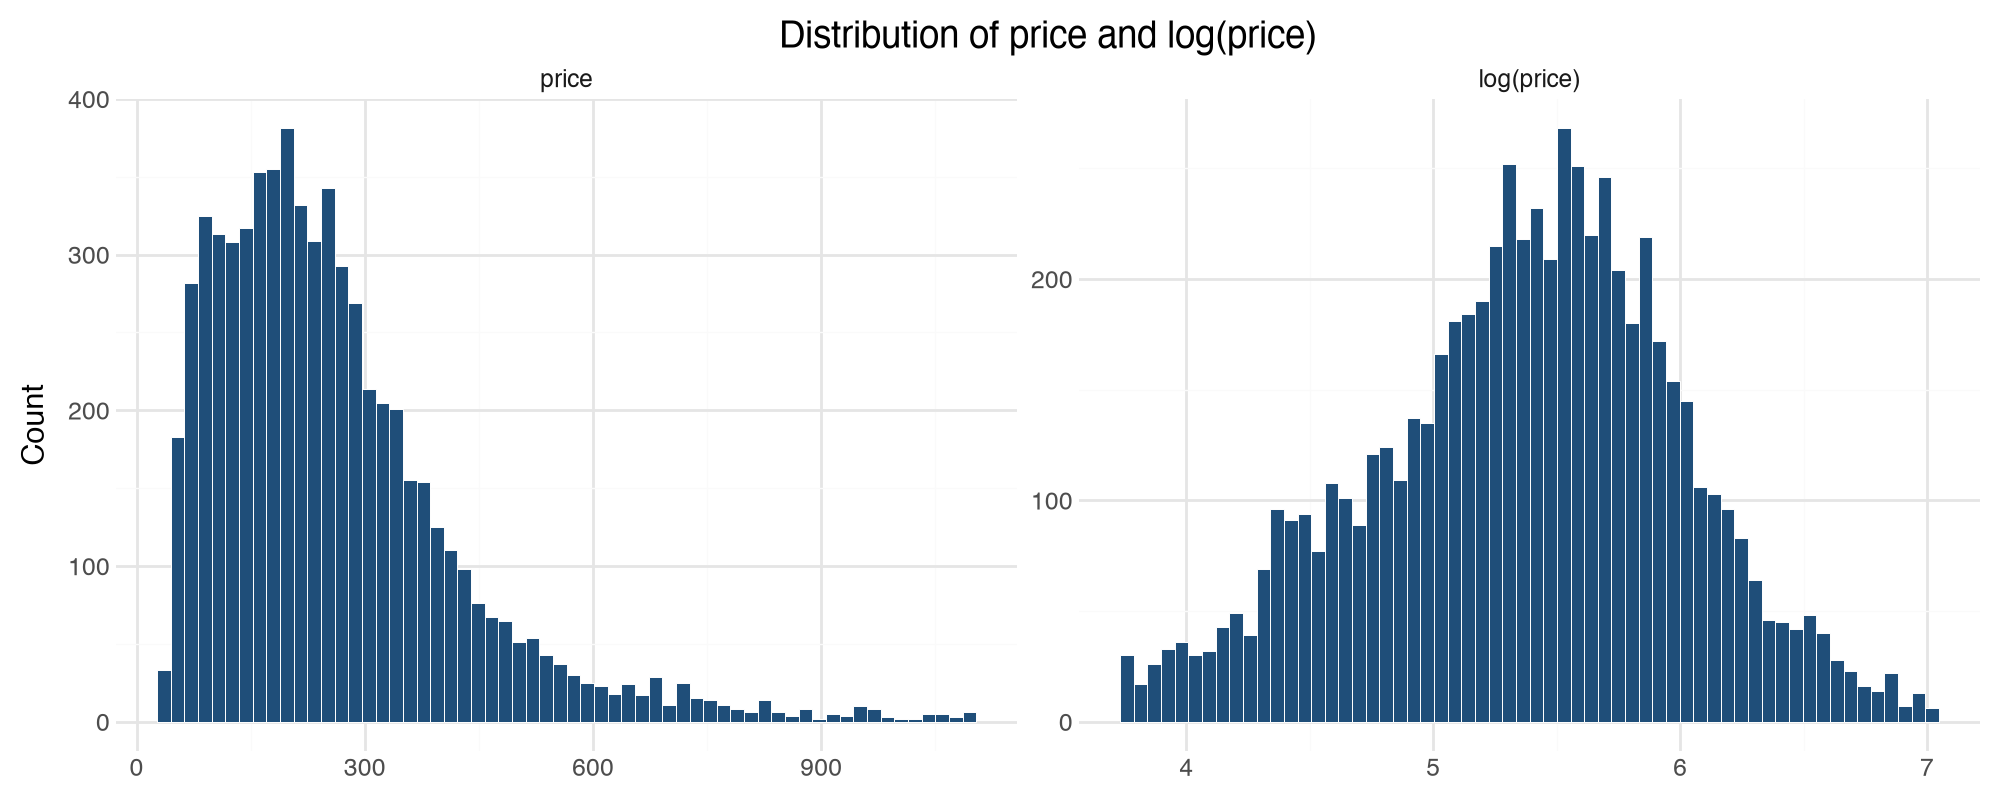

In [8]:
dist_df = pd.DataFrame({
    'scale': pd.Categorical(np.repeat(['price', 'log(price)'], len(y)), categories=['price', 'log(price)']),
    'value': np.concatenate([y, log_y]),
})

(
    ggplot(dist_df, aes('value'))
    + geom_histogram(bins=60, fill='#1f4e79', color='white', size=0.2)
    + facet_wrap('scale', scales='free')
    + labs(title='Distribution of price and log(price)', x='', y='Count')
    + theme_minimal()
    + theme(figure_size=(10, 4))
)

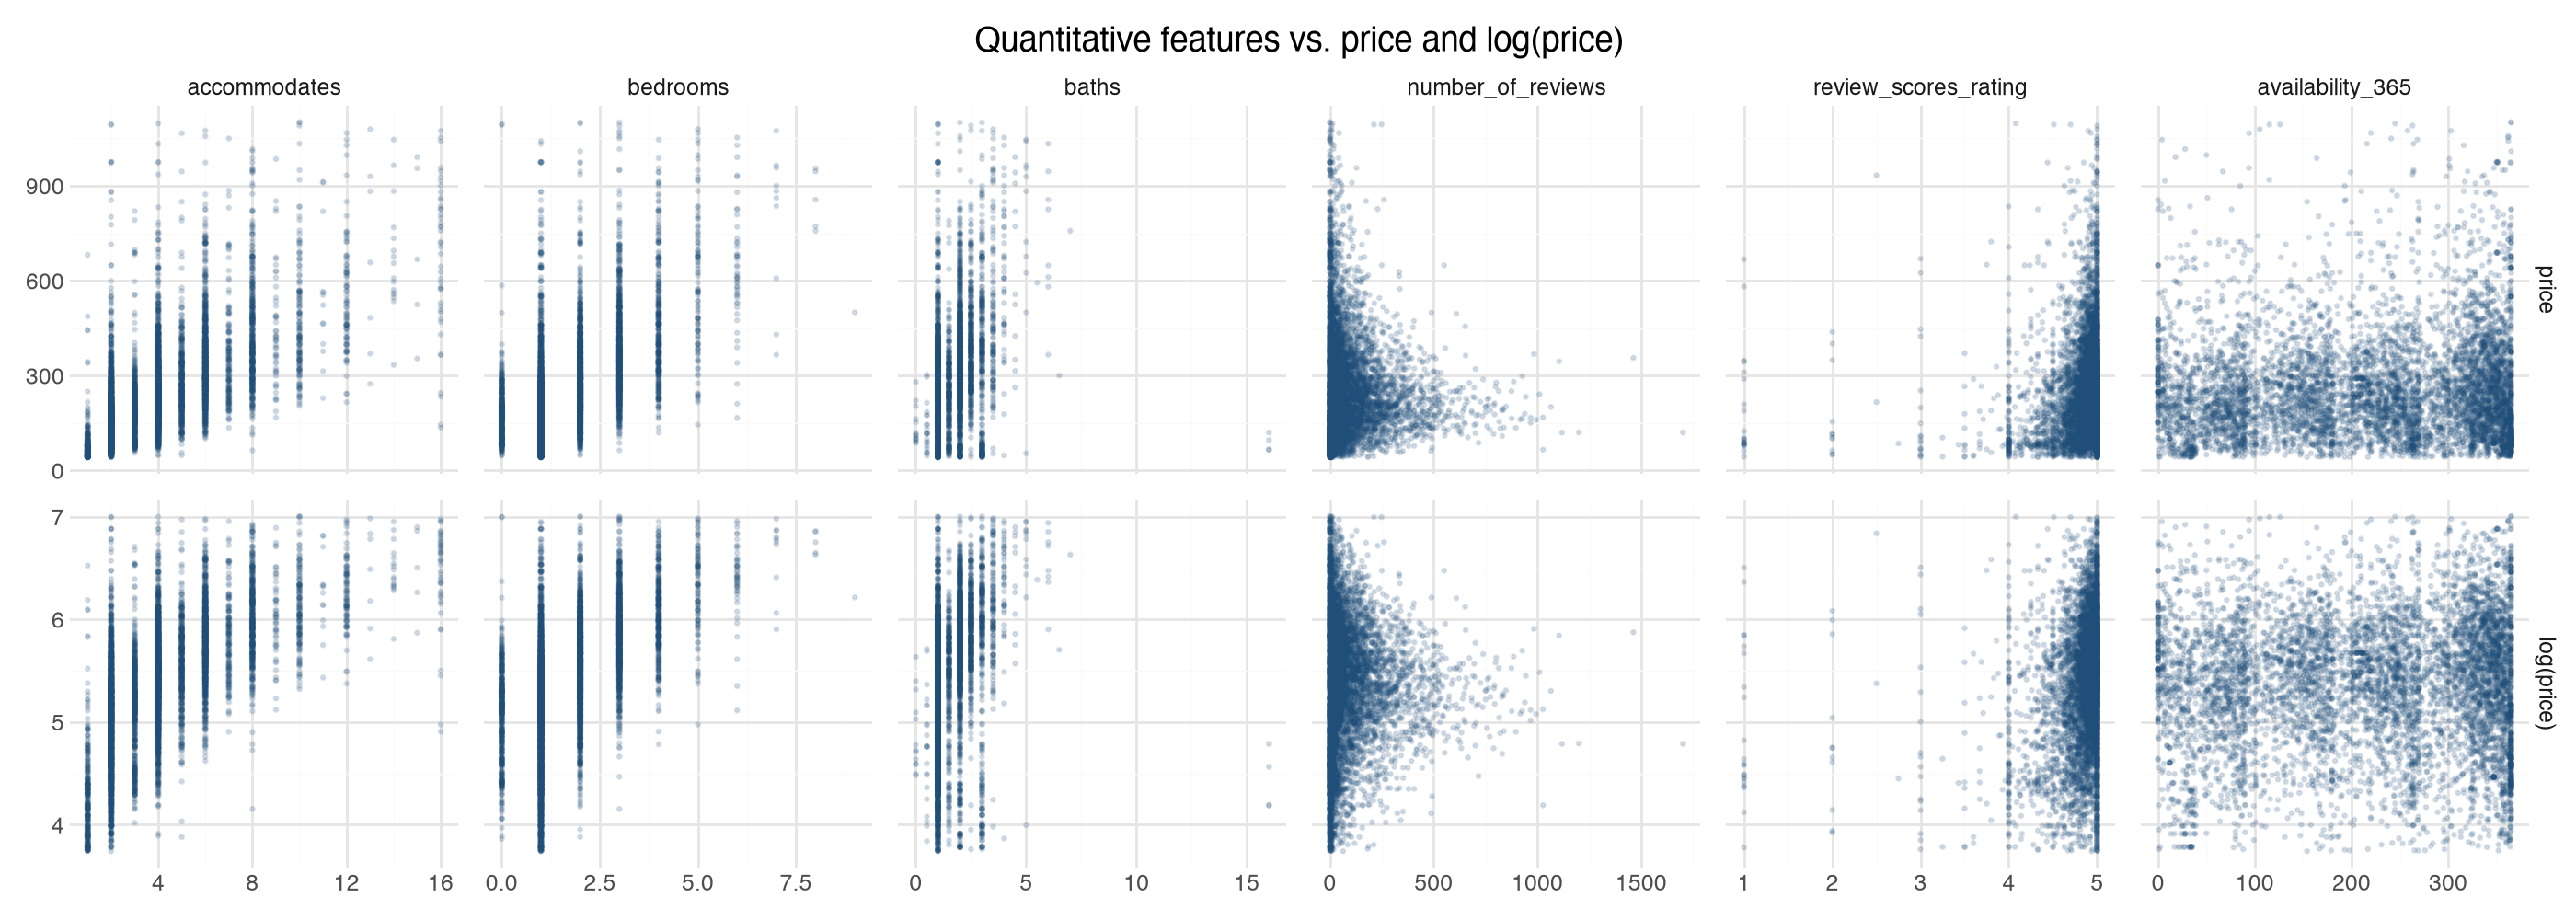

In [9]:
QUANT_FEATURES = ['accommodates', 'bedrooms', 'baths', 'number_of_reviews', 'review_scores_rating', 'availability_365']

scatter_df = (
    listings_df
    .assign(**{'log(price)': lambda d: np.log(d['price'])})
    .melt(id_vars=['price', 'log(price)'], value_vars=QUANT_FEATURES,
          var_name='feature', value_name='feature_value')
    .melt(id_vars=['feature', 'feature_value'], var_name='target', value_name='target_value')
    .dropna(subset=['feature_value'])
)
scatter_df['feature'] = pd.Categorical(scatter_df['feature'], categories=QUANT_FEATURES)
scatter_df['target'] = pd.Categorical(scatter_df['target'], categories=['price', 'log(price)'])

(
    ggplot(scatter_df, aes('feature_value', 'target_value'))
    + geom_point(alpha=0.15, size=0.4, color='#1f4e79')
    + facet_grid('target ~ feature', scales='free')
    + labs(title='Quantitative features vs. price and log(price)', x='', y='')
    + theme_minimal()
    + theme(figure_size=(14, 5))
)

# Step 2 - Fit models to predict `log(y)`

Evaluate on RMSLE. Every model predicts `log(price)`, so RMSLE is the RMSE of those predictions on the log scale.

## Model A - Linear Regression

In [10]:
lm = LinearRegression().fit(X_train, log_y_train)

print(f'Linear regression holdout RMSLE: {rmsle(log_y_holdout, lm.predict(X_holdout)):.4f}')

a_preds = export_preds(PREDS_DIR / 'a-lm-pred.pkl', lm.predict(X_all))
a_preds.head()

Linear regression holdout RMSLE: 0.3602


,row_id,split,y_pred
0,0,train,4.474781
1,1,validation,4.497613
2,2,train,5.271425
3,3,train,5.258041
4,4,holdout,5.059738


## Model B - XGBoost

In [11]:
XGB_HP_PATH = HP_DIR / 'b-xgboost-hp.json'
# Small grid with a fairly high learning rate, to favor speed. Early stopping picks n_estimators.
XGB_GRID = {
    'max_depth': [4, 6, 8],
    'min_child_weight': [1, 5],
}
XGB_FIXED_PARAMS = dict(
    learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
    tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1,
)

if XGB_HP_PATH.exists():
    xgb_hp = json.loads(XGB_HP_PATH.read_text())
    print(f'Loaded cached hyperparameters from {XGB_HP_PATH}: {xgb_hp}')
else:
    results = []
    for values in itertools.product(*XGB_GRID.values()):
        params = dict(zip(XGB_GRID, values))
        model = xgb.XGBRegressor(
            **XGB_FIXED_PARAMS, **params,
            n_estimators=2000, early_stopping_rounds=50, eval_metric='rmse',
        )
        model.fit(X_train, log_y_train, eval_set=[(X_validation, log_y_validation)], verbose=False)
        # eval_metric is RMSE on log(price), i.e. RMSLE
        results.append({**params, 'n_estimators': model.best_iteration + 1, 'val_rmsle': float(model.best_score)})
    results_df = pd.DataFrame(results).sort_values('val_rmsle')
    display(results_df)
    xgb_hp = {k: int(v) for k, v in results_df.drop(columns='val_rmsle').iloc[0].items()}
    XGB_HP_PATH.write_text(json.dumps(xgb_hp, indent=2))
    print(f'Saved best hyperparameters to {XGB_HP_PATH}: {xgb_hp}')


def fit_xgb(X, log_y):
    # n_estimators is the number of rounds early stopping found
    return xgb.XGBRegressor(**XGB_FIXED_PARAMS, **xgb_hp).fit(X, log_y)


# Fit on train only. Equivalent to the best grid-search model, but also works when the hyperparameters come from the cache
xgb_model = fit_xgb(X_train, log_y_train)

print(f'XGBoost holdout RMSLE: {rmsle(log_y_holdout, xgb_model.predict(X_holdout)):.4f}')

b_preds = export_preds(PREDS_DIR / 'b-xgboost-pred.pkl', xgb_model.predict(X_all))
b_preds.head()

Loaded cached hyperparameters from hp-cache/b-xgboost-hp.json: {'max_depth': 8, 'min_child_weight': 1, 'n_estimators': 127}
XGBoost holdout RMSLE: 0.3120


,row_id,split,y_pred
0,0,train,4.711721
1,1,validation,4.646261
2,2,train,5.325600
3,3,train,4.835425
4,4,holdout,5.076916


## Model C - Neural Net

In [12]:
NN_HP_PATH = HP_DIR / 'c-nn-hp.json'
NN_GRID = {
    'hidden_size': [64, 128],
    'lr': [1e-3, 3e-3],
}
NN_FIXED_PARAMS = {'n_layers': 2, 'batch_size': 256}
NN_MAX_EPOCHS = 200
NN_PATIENCE = 10


class MLP(nn.Module):
    def __init__(self, n_inputs, hidden_size, n_layers, out_bias):
        super().__init__()
        layers, width = [], n_inputs
        for _ in range(n_layers):
            layers += [nn.Linear(width, hidden_size), nn.ReLU()]
            width = hidden_size
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)
        with torch.no_grad():
            # Start the output at mean log(price) so early epochs aren't spent learning the intercept
            self.net[-1].bias.fill_(out_bias)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def to_tensor(a):
    return torch.as_tensor(np.asarray(a), dtype=torch.float32)


def predict_nn(model, X):
    model.eval()
    with torch.no_grad():
        return model(to_tensor(X)).numpy().astype(np.float64)


def train_nn(X, log_y, hp, n_epochs, X_val=None, log_y_val=None, desc='Training', leave=True):
    """Train for up to n_epochs. With validation data, early-stop and restore the best epoch's weights.
    Shows a per-epoch progress bar labeled `desc`; leave=False removes it when training finishes.

    Returns (model, best_epoch, best_val_rmsle). Without validation data the last two are n_epochs and inf.
    """
    torch.manual_seed(RANDOM_STATE)
    model = MLP(X.shape[1], hp['hidden_size'], hp['n_layers'], out_bias=float(np.mean(log_y)))
    optimizer = torch.optim.Adam(model.parameters(), lr=hp['lr'])
    loss_fn = nn.MSELoss()  # MSE on log(price) is MSLE on price
    X_t, y_t = to_tensor(X), to_tensor(log_y)
    generator = torch.Generator().manual_seed(RANDOM_STATE)

    best_rmsle, best_epoch, best_state = float('inf'), n_epochs, None
    epochs = tqdm(range(1, n_epochs + 1), desc=desc, unit='epoch', leave=leave)
    for epoch in epochs:
        model.train()
        for batch in torch.randperm(len(X_t), generator=generator).split(hp['batch_size']):
            optimizer.zero_grad()
            loss_fn(model(X_t[batch]), y_t[batch]).backward()
            optimizer.step()

        if X_val is None:
            continue
        val_rmsle = rmsle(log_y_val, predict_nn(model, X_val))
        if val_rmsle < best_rmsle:
            best_rmsle, best_epoch, best_state = val_rmsle, epoch, copy.deepcopy(model.state_dict())
        epochs.set_postfix(val_rmsle=f'{val_rmsle:.4f}', best=f'{best_rmsle:.4f} @ epoch {best_epoch}')
        if epoch - best_epoch >= NN_PATIENCE:
            break  # early stop: the bar stays at the epoch where training stopped
    epochs.close()

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_epoch, best_rmsle


if NN_HP_PATH.exists():
    nn_hp = json.loads(NN_HP_PATH.read_text())
    print(f'Loaded cached hyperparameters from {NN_HP_PATH}: {nn_hp}')
else:
    results = []
    grid = list(itertools.product(*NN_GRID.values()))
    for values in tqdm(grid, desc='NN grid search', unit='config'):
        hp = {**NN_FIXED_PARAMS, **dict(zip(NN_GRID, values))}
        _, best_epoch, val_rmsle = train_nn(
            X_train, log_y_train, hp, NN_MAX_EPOCHS, X_validation, log_y_validation,
            desc=f"hidden_size={hp['hidden_size']}, lr={hp['lr']}", leave=False,
        )
        results.append({**hp, 'n_epochs': best_epoch, 'val_rmsle': val_rmsle})
    display(pd.DataFrame(results).sort_values('val_rmsle'))
    best = min(results, key=lambda r: r['val_rmsle'])
    nn_hp = {k: v for k, v in best.items() if k != 'val_rmsle'}
    NN_HP_PATH.write_text(json.dumps(nn_hp, indent=2))
    print(f'Saved best hyperparameters to {NN_HP_PATH}: {nn_hp}')

# Fit on train only for the number of epochs early stopping found. Same seed, so this reproduces the best
# grid-search model, and it also works when the hyperparameters come from the cache.
nn_model, _, _ = train_nn(X_train, log_y_train, nn_hp, nn_hp['n_epochs'], desc='Final fit on train')

print(f'Neural net holdout RMSLE: {rmsle(log_y_holdout, predict_nn(nn_model, X_holdout)):.4f}')

c_preds = export_preds(PREDS_DIR / 'c-nn-pred.pkl', predict_nn(nn_model, X_all))
c_preds.head()

Loaded cached hyperparameters from hp-cache/c-nn-hp.json: {'n_layers': 2, 'batch_size': 256, 'hidden_size': 128, 'lr': 0.003, 'n_epochs': 19}


Final fit on train:   0%|          | 0/19 [00:00<?, ?epoch/s]

Neural net holdout RMSLE: 0.3320


,row_id,split,y_pred
0,0,train,4.489191
1,1,validation,4.628650
2,2,train,5.417655
3,3,train,5.230398
4,4,holdout,5.071477


In [13]:
# Reads from preds-cache/, so this works even if the model cells above were skipped
MODEL_FILES = {'lm': 'a-lm-pred.pkl', 'xgboost': 'b-xgboost-pred.pkl', 'nn': 'c-nn-pred.pkl'}

preds_df = pd.DataFrame({'y': y, 'split': listings_df['split']}, index=listings_df.index)
for model_name, filename in MODEL_FILES.items():
    model_preds = pd.read_pickle(PREDS_DIR / filename).set_index('row_id')
    preds_df[f'y_pred_{model_name}'] = model_preds['y_pred']

preds_df.head()

,y,split,y_pred_lm,y_pred_xgboost,y_pred_nn
0,113.02,train,4.474781,4.711721,4.489191
1,86.00,validation,4.497613,4.646261,4.628650
2,203.94,train,5.271425,5.325600,5.417655
3,120.50,train,5.258041,4.835425,5.230398
4,152.59,holdout,5.059738,5.076916,5.071477


# Step 3 - Summarize Initial Results

In [14]:
# Steps 3 and 4 report holdout results only; train/validation predictions are (partly) in-sample.
holdout_preds_df = preds_df[preds_df['split'] == 'holdout']

naive_long_df = pd.concat(
    [
        pd.DataFrame({
            'model': MODEL_LABELS[m],
            'y': holdout_preds_df['y'],
            'y_pred': holdout_preds_df[f'y_pred_{m}'],
        })
        for m in MODEL_LABELS
    ],
    ignore_index=True,
).assign(
    y_hat=lambda d: np.exp(d['y_pred']),
    log_y=lambda d: np.log(d['y']),
    resid=lambda d: np.log(d['y']) - d['y_pred'],
)
naive_long_df['model'] = pd.Categorical(naive_long_df['model'], categories=MODEL_ORDER)


def calibration_ratio(df, pred_col, by, n_bins=10):  # ~1,300 holdout rows, so 10 bins
    """Put rows into quantile bins of predicted price (within each group in `by`) and compare mean
    predicted to mean actual price per bin. A ratio above 1 means the predictions are too high on average."""
    binned = df.assign(
        bin=df.groupby(by, observed=True)[pred_col].transform(lambda s: pd.qcut(s, n_bins, labels=False))
    )
    return (
        binned.groupby([*by, 'bin'], observed=True)
        .agg(mean_pred=(pred_col, 'mean'), mean_y=('y', 'mean'))
        .reset_index()
        .assign(ratio=lambda d: d['mean_pred'] / d['mean_y'])
    )


def over_under_labels(calib_df, value_col='ratio', baseline=1.0):
    """Labels for the regions above and below the baseline (ratio = 1, or difference = 0), for a calibration plot.

    Above the line, predicted > actual, so the model over-predicts; below it, the model under-predicts.
    The labels sit symmetrically around 1, so both regions are visible even if every point is on one side.
    """
    d = 1.15 * max((calib_df[value_col] - baseline).abs().max(), 0.05)
    x = calib_df['mean_pred'].min()
    return [
        annotate('text', x=x, y=baseline + d, label='\u2191 Over-predicting (predicted > actual)',
                 ha='left', va='top', size=9, color='#555555'),
        annotate('text', x=x, y=baseline - d, label='\u2193 Under-predicting (predicted < actual)',
                 ha='left', va='bottom', size=9, color='#555555'),
    ]


def calibration_difference(df, pred_col, actual_col, by, n_bins=10):
    """Log-scale analogue of calibration_ratio: quantile bins of the prediction (within each group in `by`),
    comparing mean prediction to mean actual by subtraction. Above 0 means the predictions are too high."""
    binned = df.assign(
        bin=df.groupby(by, observed=True)[pred_col].transform(lambda s: pd.qcut(s, n_bins, labels=False))
    )
    return (
        binned.groupby([*by, 'bin'], observed=True)
        .agg(mean_pred=(pred_col, 'mean'), mean_actual=(actual_col, 'mean'))
        .reset_index()
        .assign(difference=lambda d: d['mean_pred'] - d['mean_actual'])
    )


def with_bar_labels(df, value_col, fmt, pad_frac=0.12):
    """Add `label` (formatted value) and `label_y` (just past the end of each bar) for bar-end labels.
    Returns the frame and the padding used, so the axis can be widened to fit the labels."""
    span = max(df[value_col].max(), 0) - min(df[value_col].min(), 0)
    pad = pad_frac * span
    out = df.assign(
        label=df[value_col].map(fmt),
        label_y=df[value_col] + np.where(df[value_col] < 0, -pad, pad),
    )
    return out, pad


def dollars(v):
    return f"{'-' if v < 0 else '+'}${abs(v):,.2f}"

## `log(actual price)` vs. `y_pred`

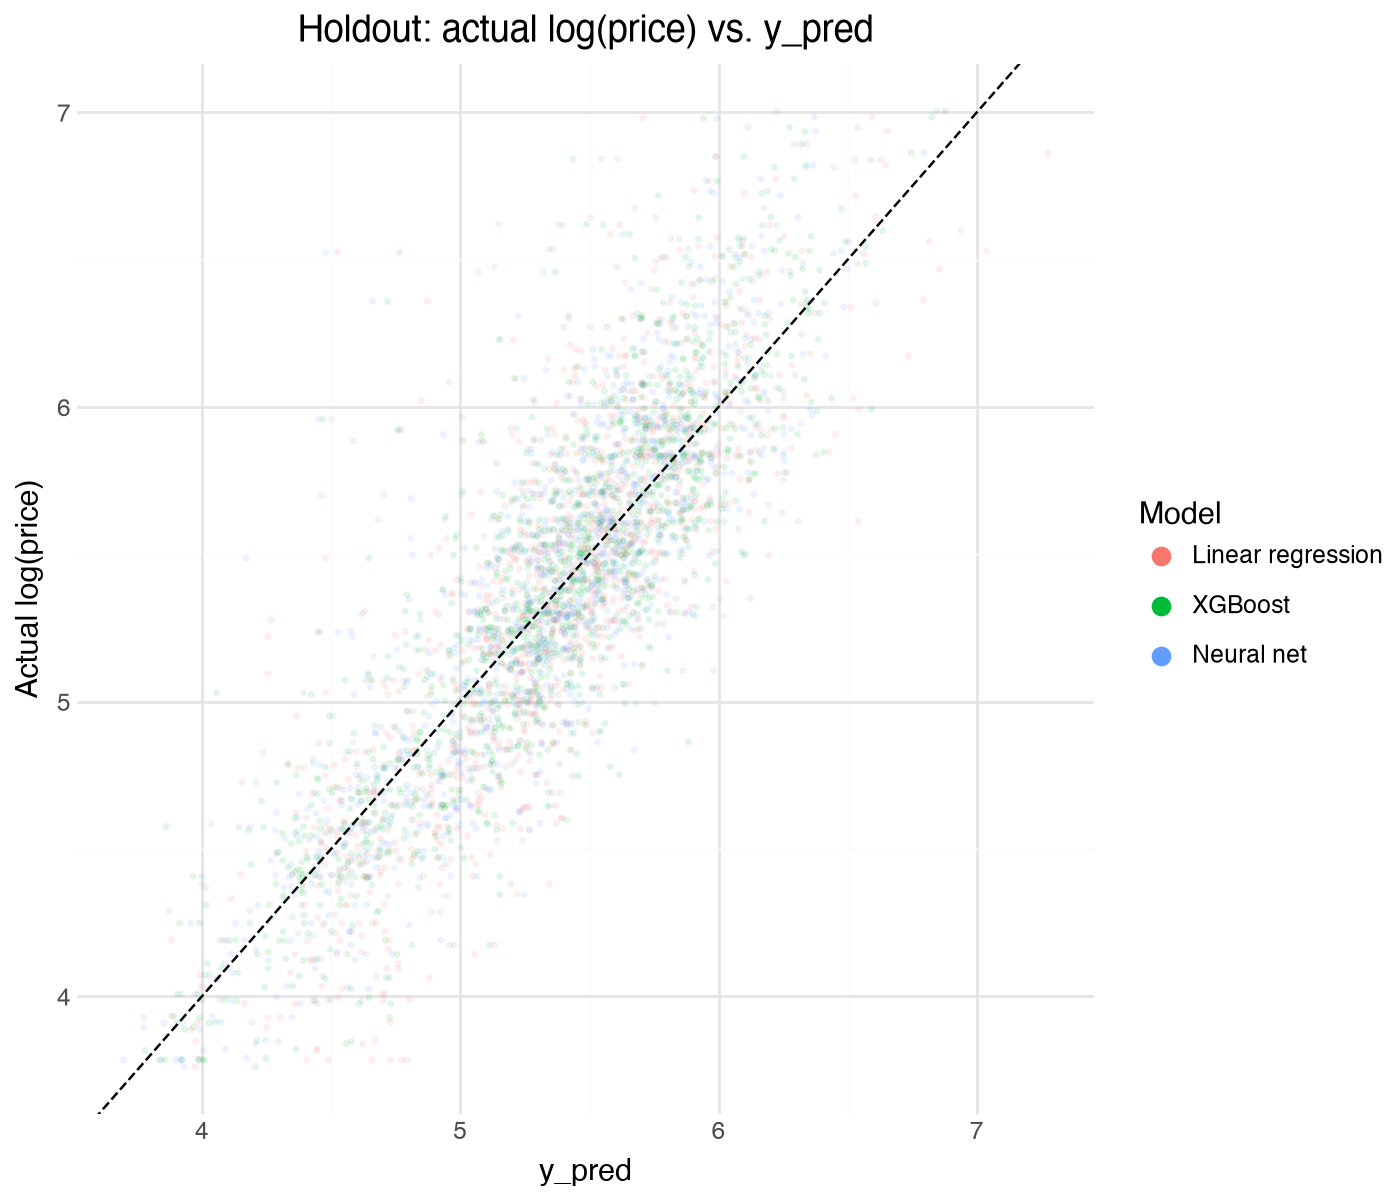

In [15]:
(
    ggplot(naive_long_df, aes('y_pred', 'log_y', color='model'))
    + geom_point(alpha=0.08, size=0.5)
    + geom_abline(slope=1, intercept=0, linetype='dashed')
    + guides(color=guide_legend(override_aes={'alpha': 1, 'size': 3}))
    + labs(title='Holdout: actual log(price) vs. y_pred', x='y_pred', y='Actual log(price)', color='Model')
    + theme_minimal()
    + theme(figure_size=(7, 6))
)

/Users/bsherman/transformation-bias-demo/.venv/lib/python3.14/site-packages/plotnine/ggplot.py:695: UserWarning: Glyph 8593 (\N{UPWARDS ARROW}) missing from font(s) Helvetica.
/Users/bsherman/transformation-bias-demo/.venv/lib/python3.14/site-packages/plotnine/ggplot.py:695: UserWarning: Glyph 8595 (\N{DOWNWARDS ARROW}) missing from font(s) Helvetica.


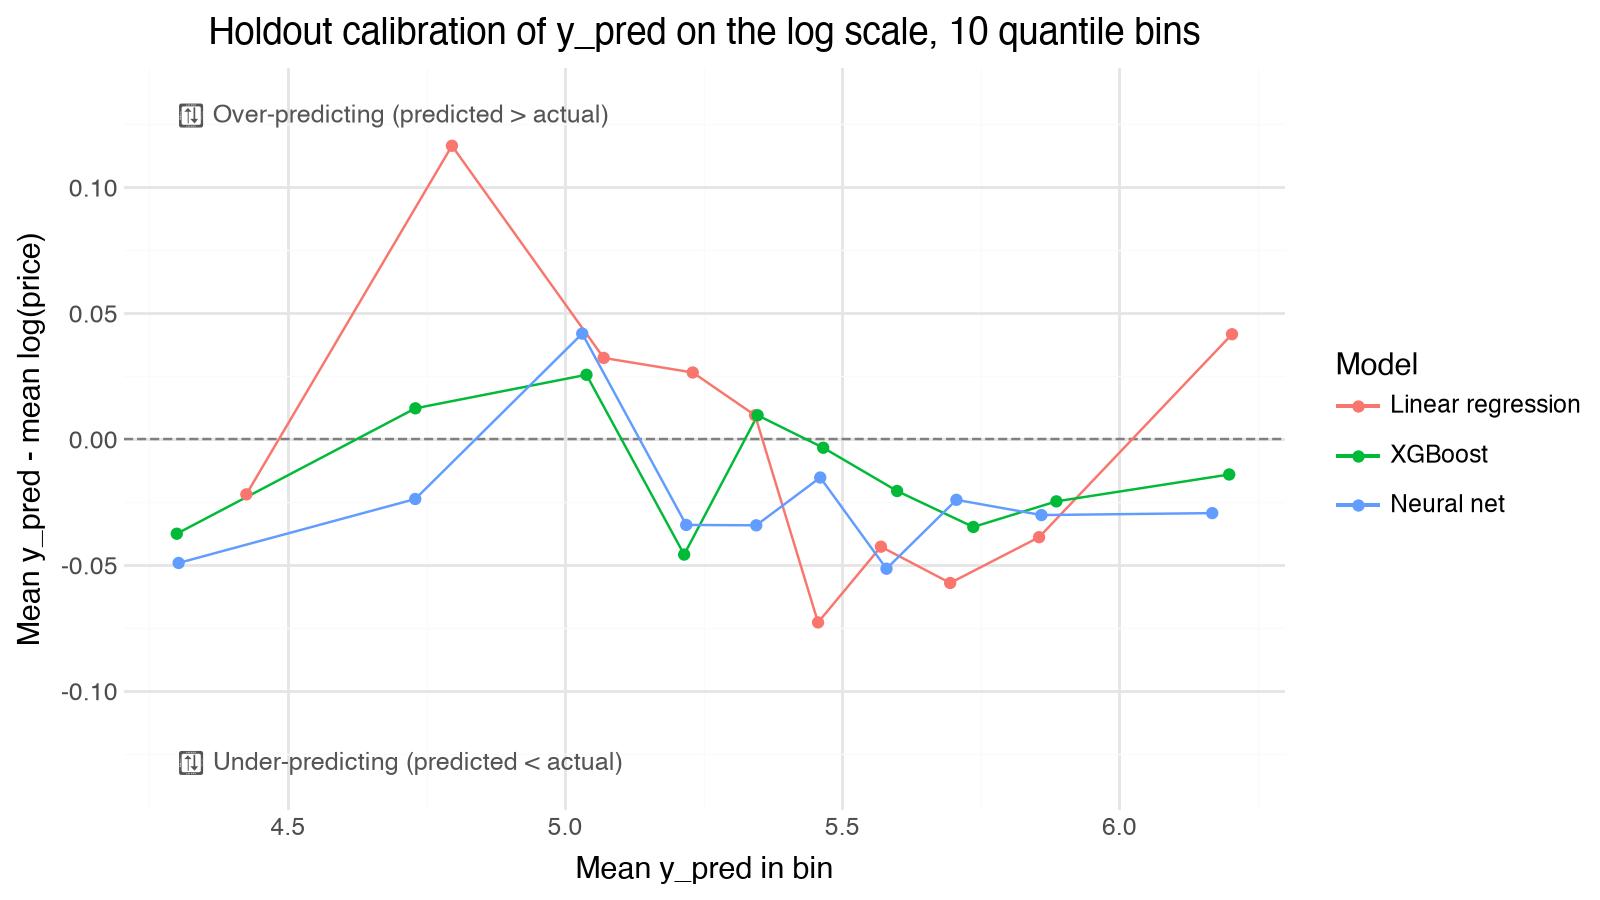

In [16]:
# Log-scale version of the calibration plot below. Uses a difference instead of a ratio, since a difference
# in log(price) is (approximately) a relative error: 0.05 is about 5% over.
log_calib_df = calibration_difference(naive_long_df, 'y_pred', 'log_y', ['model'])
(
    ggplot(log_calib_df, aes('mean_pred', 'difference', color='model'))
    + geom_hline(yintercept=0, linetype='dashed', color='gray')
    + over_under_labels(log_calib_df, value_col='difference', baseline=0)
    + geom_line()
    + geom_point()
    + labs(
        title='Holdout calibration of y_pred on the log scale, 10 quantile bins',
        x='Mean y_pred in bin', y='Mean y_pred - mean log(price)', color='Model',
    )
    + theme_minimal()
    + theme(figure_size=(8, 4.5))
)

In [17]:
# Log-scale bias = mean(y_pred - log(price)) on holdout; near 0 means the model is unbiased for log(price)
log_bias_df = (
    naive_long_df.groupby('model', observed=True)
    .agg(
        rmsle=('resid', lambda r: np.sqrt(np.mean(r ** 2))),
        mean_log_y=('log_y', 'mean'),
        mean_y_pred=('y_pred', 'mean'),
    )
    .assign(log_bias=lambda d: d['mean_y_pred'] - d['mean_log_y'])
)
log_bias_df.round(4)

,rmsle,mean_log_y,mean_y_pred,log_bias
model,,,,
Linear regression,0.3602,5.3647,5.3641,-0.0006
XGBoost,0.3120,5.3647,5.3514,-0.0133
Neural net,0.3320,5.3647,5.3398,-0.0249


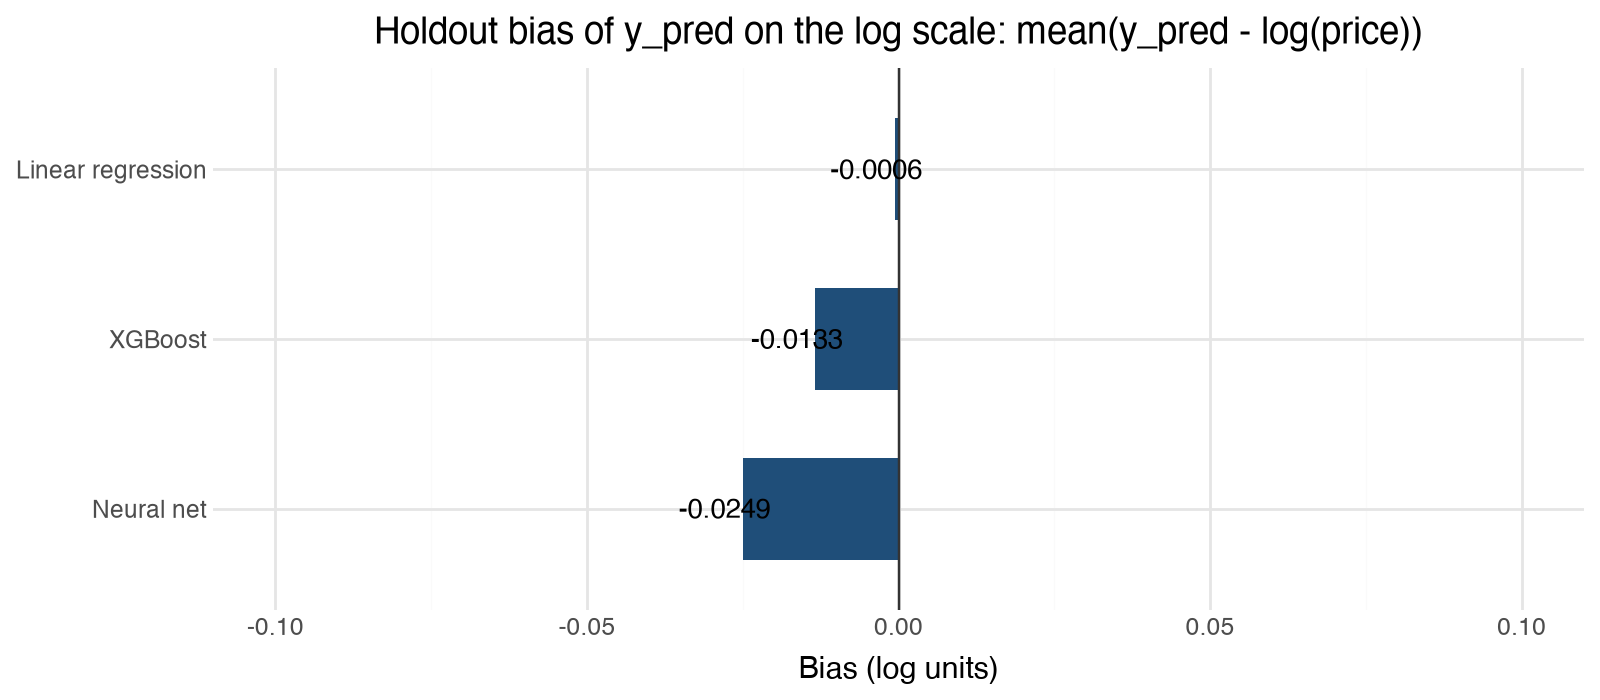

In [18]:
log_bias_plot_df, pad = with_bar_labels(log_bias_df.reset_index(), 'log_bias', lambda v: f'{v:+.4f}')

(
    ggplot(log_bias_plot_df, aes('model', 'log_bias'))
    + geom_col(fill='#1f4e79', width=0.6)
    + geom_hline(yintercept=0, color='#333333')
    + geom_text(aes(y='label_y', label='label'), size=10)
    + scale_x_discrete(limits=MODEL_ORDER[::-1])
    # Fixed +/-0.1 axis (about +/-10%) so a near-zero bias looks near zero, comparable to the price-scale chart
    + expand_limits(y=[-0.1, 0.1, log_bias_plot_df['label_y'].min() - pad, log_bias_plot_df['label_y'].max() + pad])
    + coord_flip()
    + labs(title='Holdout bias of y_pred on the log scale: mean(y_pred - log(price))', x='', y='Bias (log units)')
    + theme_minimal()
    + theme(figure_size=(8, 3.5))
)

## `actual price` vs. `exp(y_pred)`

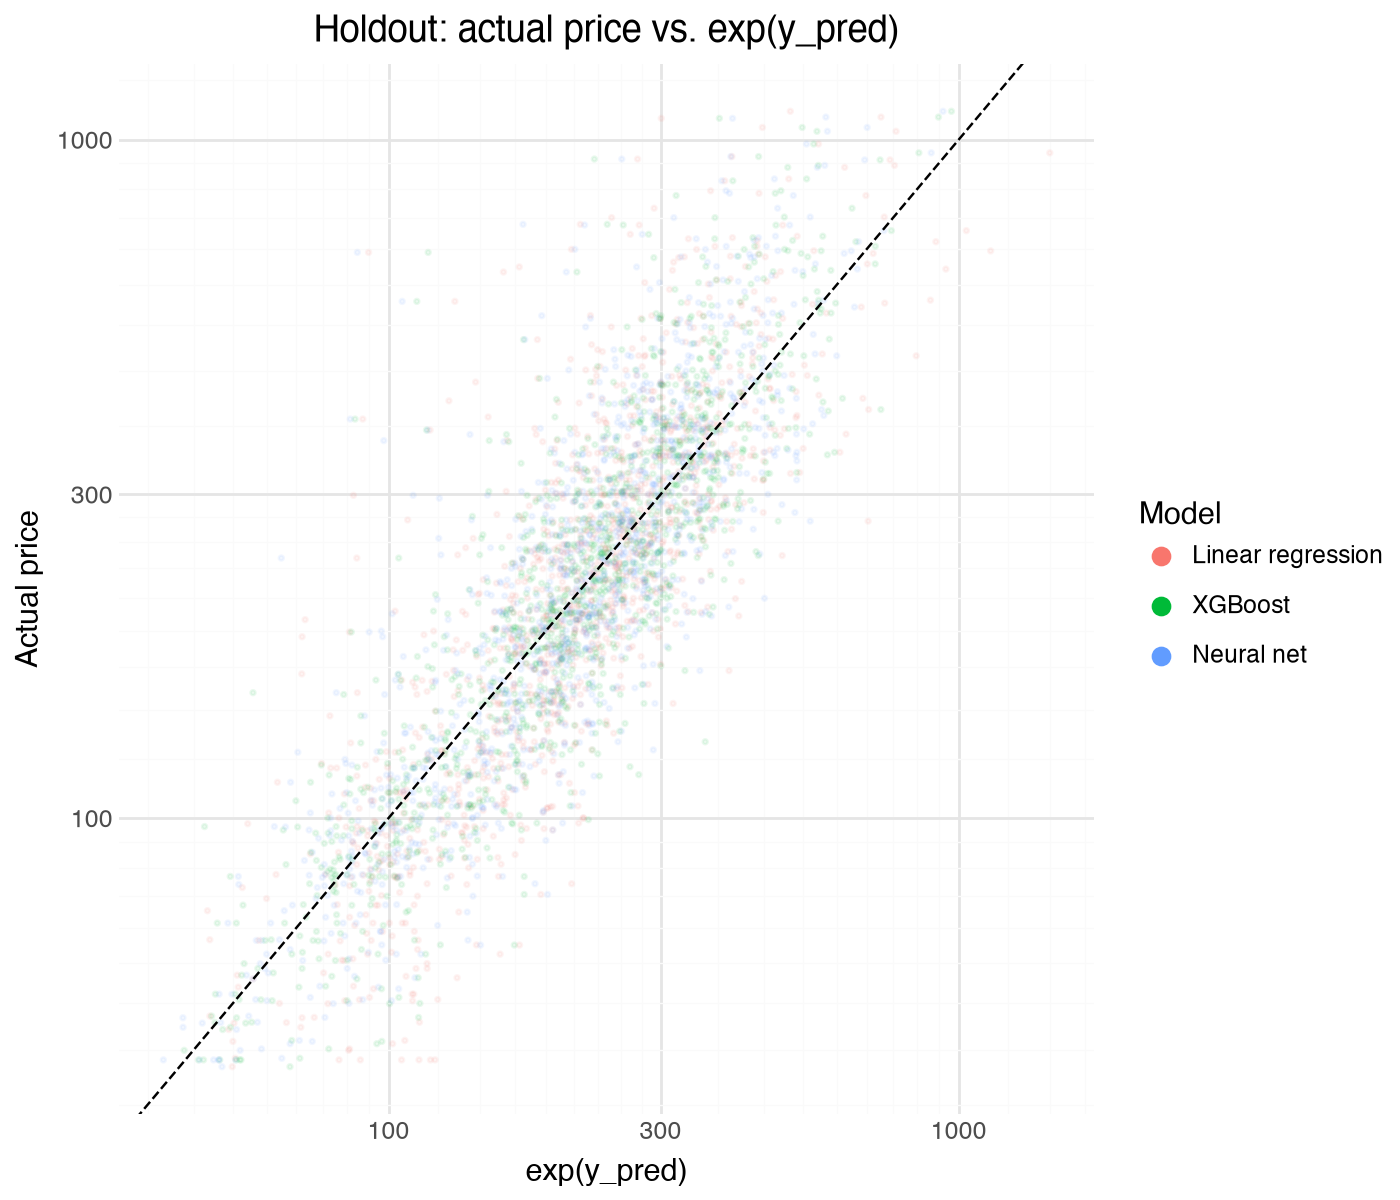

In [19]:
(
    ggplot(naive_long_df, aes('y_hat', 'y', color='model'))
    + geom_point(alpha=0.08, size=0.5)
    + geom_abline(slope=1, intercept=0, linetype='dashed')
    + scale_x_log10()
    + scale_y_log10()
    + guides(color=guide_legend(override_aes={'alpha': 1, 'size': 3}))
    + labs(title='Holdout: actual price vs. exp(y_pred)', x='exp(y_pred)', y='Actual price', color='Model')
    + theme_minimal()
    + theme(figure_size=(7, 6))
)

/Users/bsherman/transformation-bias-demo/.venv/lib/python3.14/site-packages/plotnine/ggplot.py:695: UserWarning: Glyph 8593 (\N{UPWARDS ARROW}) missing from font(s) Helvetica.
/Users/bsherman/transformation-bias-demo/.venv/lib/python3.14/site-packages/plotnine/ggplot.py:695: UserWarning: Glyph 8595 (\N{DOWNWARDS ARROW}) missing from font(s) Helvetica.


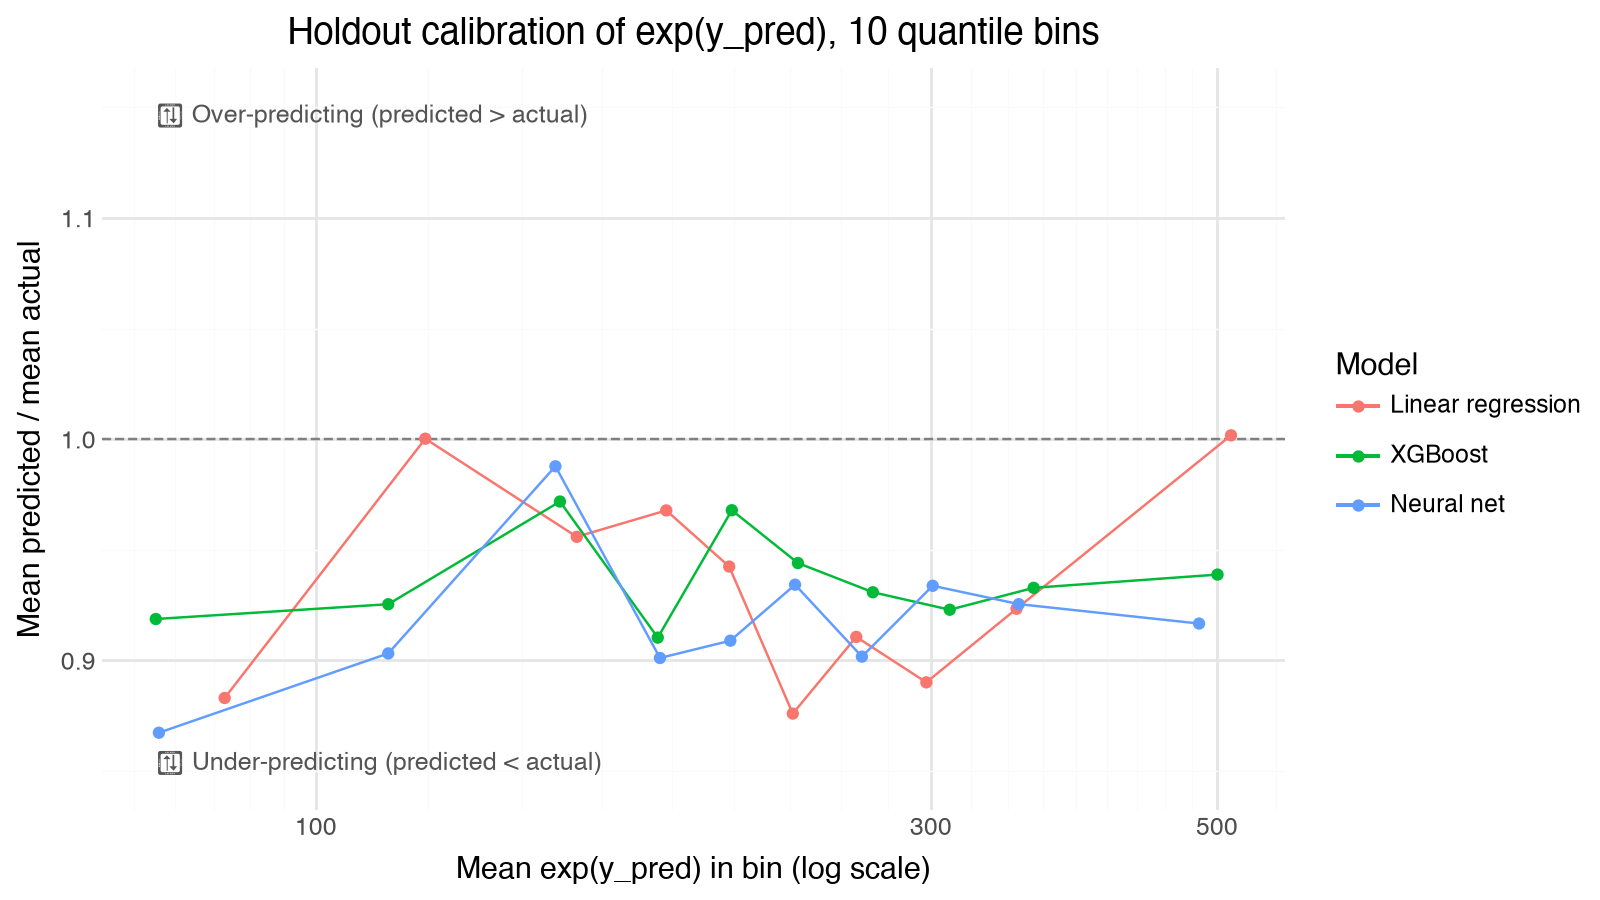

In [20]:
# The scatter can't show a bias of a few percent, so also bin by prediction and plot mean actual / mean predicted
naive_calib_df = calibration_ratio(naive_long_df, 'y_hat', ['model'])
(
    ggplot(naive_calib_df, aes('mean_pred', 'ratio', color='model'))
    + geom_hline(yintercept=1, linetype='dashed', color='gray')
    + over_under_labels(naive_calib_df)
    + geom_line()
    + geom_point()
    + scale_x_log10()
    + labs(
        title='Holdout calibration of exp(y_pred), 10 quantile bins',
        x='Mean exp(y_pred) in bin (log scale)', y='Mean predicted / mean actual', color='Model',
    )
    + theme_minimal()
    + theme(figure_size=(8, 4.5))
)

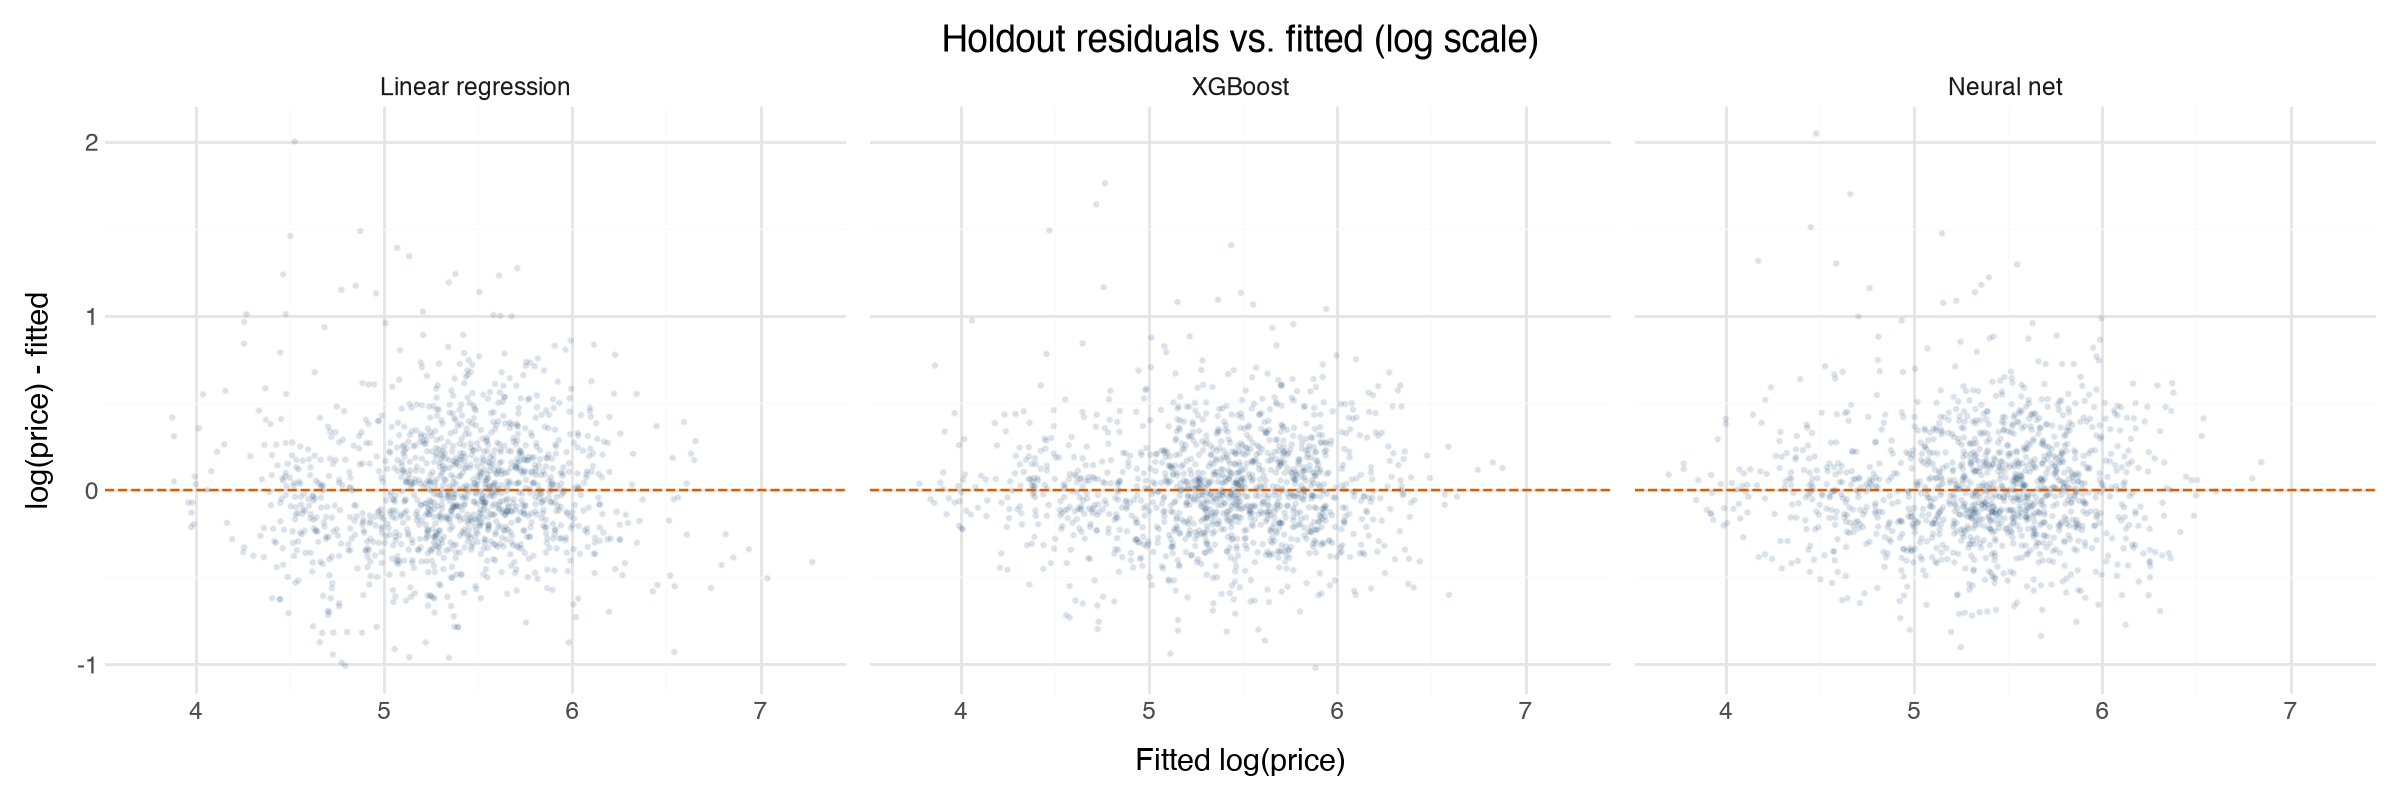

In [21]:
(
    ggplot(naive_long_df, aes('y_pred', 'resid'))
    + geom_point(alpha=0.1, size=0.4, color='#1f4e79')
    + geom_hline(yintercept=0, linetype='dashed', color='#d95f02')
    + facet_wrap('model', ncol=3)
    + labs(title='Holdout residuals vs. fitted (log scale)', x='Fitted log(price)', y='log(price) - fitted')
    + theme_minimal()
    + theme(figure_size=(12, 4))
)

In [22]:
# bias = mean(exp(y_pred) - y) on holdout; negative means under-prediction
bias_df = (
    naive_long_df.groupby('model', observed=True)
    .agg(
        rmsle=('resid', lambda r: np.sqrt(np.mean(r ** 2))),
        mean_y=('y', 'mean'),
        mean_pred=('y_hat', 'mean'),
    )
    .assign(
        bias=lambda d: d['mean_pred'] - d['mean_y'],
        pct_bias=lambda d: 100 * (d['mean_pred'] / d['mean_y'] - 1),
    )
)
bias_df.round(4)

,rmsle,mean_y,mean_pred,bias,pct_bias
model,,,,,
Linear regression,0.3602,257.9645,241.8480,-16.1165,-6.2476
XGBoost,0.3120,257.9645,241.5684,-16.3961,-6.3560
Neural net,0.3320,257.9645,237.3637,-20.6008,-7.9859


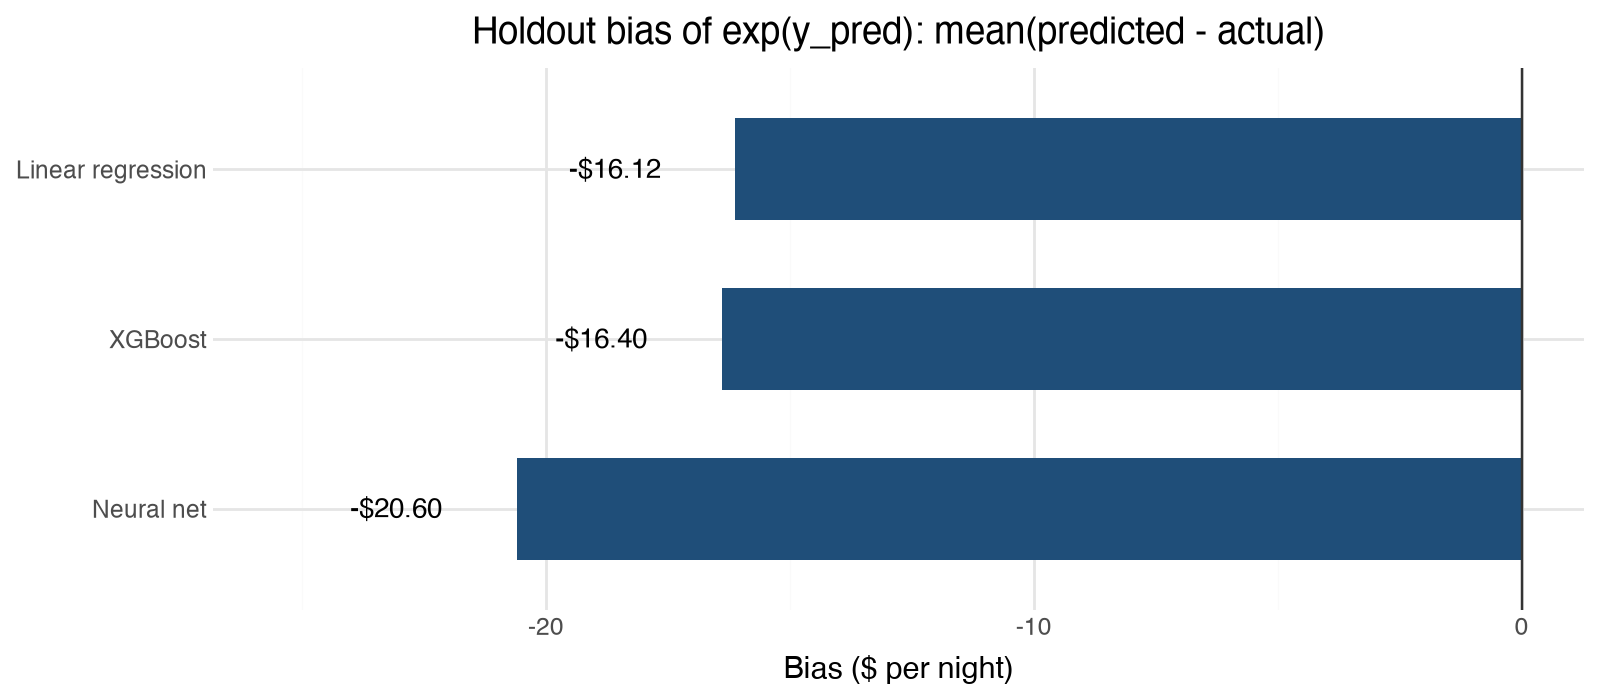

In [23]:
bias_plot_df, pad = with_bar_labels(bias_df.reset_index(), 'bias', dollars)

(
    ggplot(bias_plot_df, aes('model', 'bias'))
    + geom_col(fill='#1f4e79', width=0.6)
    + geom_hline(yintercept=0, color='#333333')
    + geom_text(aes(y='label_y', label='label'), size=10)
    + scale_x_discrete(limits=MODEL_ORDER[::-1])  # first model on top after coord_flip
    + expand_limits(y=[bias_plot_df['label_y'].min() - pad, bias_plot_df['label_y'].max() + pad, 0])
    + coord_flip()
    + labs(title='Holdout bias of exp(y_pred): mean(predicted - actual)', x='', y='Bias ($ per night)')
    + theme_minimal()
    + theme(figure_size=(8, 3.5))
)

# Step 4 - Adjust predictions for transformation bias

## Naive lognormal adjustment

If the log-scale errors are normal with constant variance, $\log y = f(x) + \varepsilon$ with $\varepsilon \sim N(0, \sigma^2)$, then
$E[y \mid x] = \exp(f(x)) \cdot E[e^{\varepsilon}] = \exp(f(x) + \sigma^2/2)$.
So the correction is one constant factor, $e^{\sigma^2/2}$, with $\sigma^2$ estimated from residuals. It's exact if the normality assumption holds, and off by however much it doesn't: heavy tails or skew in the residuals make it wrong. Duan's smearing, below, drops the normality assumption.

In [24]:
def lognormal_adjust_preds(log_y_pred, residuals):
    """Naive lognormal retransformation: exp(y_pred) * exp(sigma^2 / 2).

    sigma^2 is the mean squared residual (the usual regression error-variance estimate, taking the errors
    to have mean 0). residuals: log(y) - predicted log(y) on reference data (ideally out-of-sample).
    Returns (adjusted predictions on the price scale, adjustment factor).
    """
    sigma2 = float(np.mean(np.asarray(residuals) ** 2))
    factor = float(np.exp(sigma2 / 2))
    return np.exp(np.asarray(log_y_pred)) * factor, factor


# Same out-of-sample residuals as smearing below: each model's residuals on the validation split
is_validation_row = preds_df['split'] == 'validation'
lognormal_factors = {}
for m in MODEL_LABELS:
    validation_resid = (
        np.log(preds_df.loc[is_validation_row, 'y']) - preds_df.loc[is_validation_row, f'y_pred_{m}']
    )
    preds_df[f'lognormal_y_pred_{m}'], lognormal_factors[m] = lognormal_adjust_preds(
        preds_df[f'y_pred_{m}'], validation_resid,
    )

pd.Series({MODEL_LABELS[m]: factor for m, factor in lognormal_factors.items()}, name='lognormal_factor')

Linear regression    1.067861
XGBoost              1.049049
Neural net           1.056427
Name: lognormal_factor, dtype: float64

## Duan's smearing (nonparametric)

In [25]:
# TODO Add a Markdown cell here containing a similar explanation to that of the lognormal one

In [26]:
def smear_preds(log_y_pred, residuals):
    """Duan's (1983) smearing estimator.

    A model of log(y) estimates E[log y | x]. exp() of that is a conditional geometric mean, which is
    below the conditional mean (Jensen). If log y = f(x) + eps with eps independent of x, then
    E[y | x] = exp(f(x)) * E[exp(eps)]. Duan estimates E[exp(eps)] nonparametrically as the mean of exp(residuals).

    log_y_pred: predictions on the log scale.
    residuals: log(y) - predicted log(y) on reference data (ideally out-of-sample).
    Returns (smeared predictions on the price scale, smearing factor).
    """
    smear_factor = float(np.mean(np.exp(np.asarray(residuals))))
    return np.exp(np.asarray(log_y_pred)) * smear_factor, smear_factor

In [27]:
# The smearing factor comes from out-of-sample residuals: each model's residuals on the validation split,
# which it never trained on. In-sample residuals from flexible models (XGBoost, the NN) are shrunk by
# overfitting, which would understate the correction.
is_validation_row = preds_df['split'] == 'validation'
smear_factors = {}
for m in MODEL_LABELS:
    validation_resid = (
        np.log(preds_df.loc[is_validation_row, 'y']) - preds_df.loc[is_validation_row, f'y_pred_{m}']
    )
    preds_df[f'smeared_y_pred_{m}'], smear_factors[m] = smear_preds(preds_df[f'y_pred_{m}'], validation_resid)

pd.DataFrame({
    'lognormal_factor': {MODEL_LABELS[m]: f for m, f in lognormal_factors.items()},
    'smear_factor': {MODEL_LABELS[m]: f for m, f in smear_factors.items()},
}).round(4)

,lognormal_factor,smear_factor
Linear regression,1.0679,1.0722
XGBoost,1.0490,1.0570
Neural net,1.0564,1.0805


/Users/bsherman/transformation-bias-demo/.venv/lib/python3.14/site-packages/plotnine/ggplot.py:695: UserWarning: Glyph 8593 (\N{UPWARDS ARROW}) missing from font(s) Helvetica.
/Users/bsherman/transformation-bias-demo/.venv/lib/python3.14/site-packages/plotnine/ggplot.py:695: UserWarning: Glyph 8595 (\N{DOWNWARDS ARROW}) missing from font(s) Helvetica.


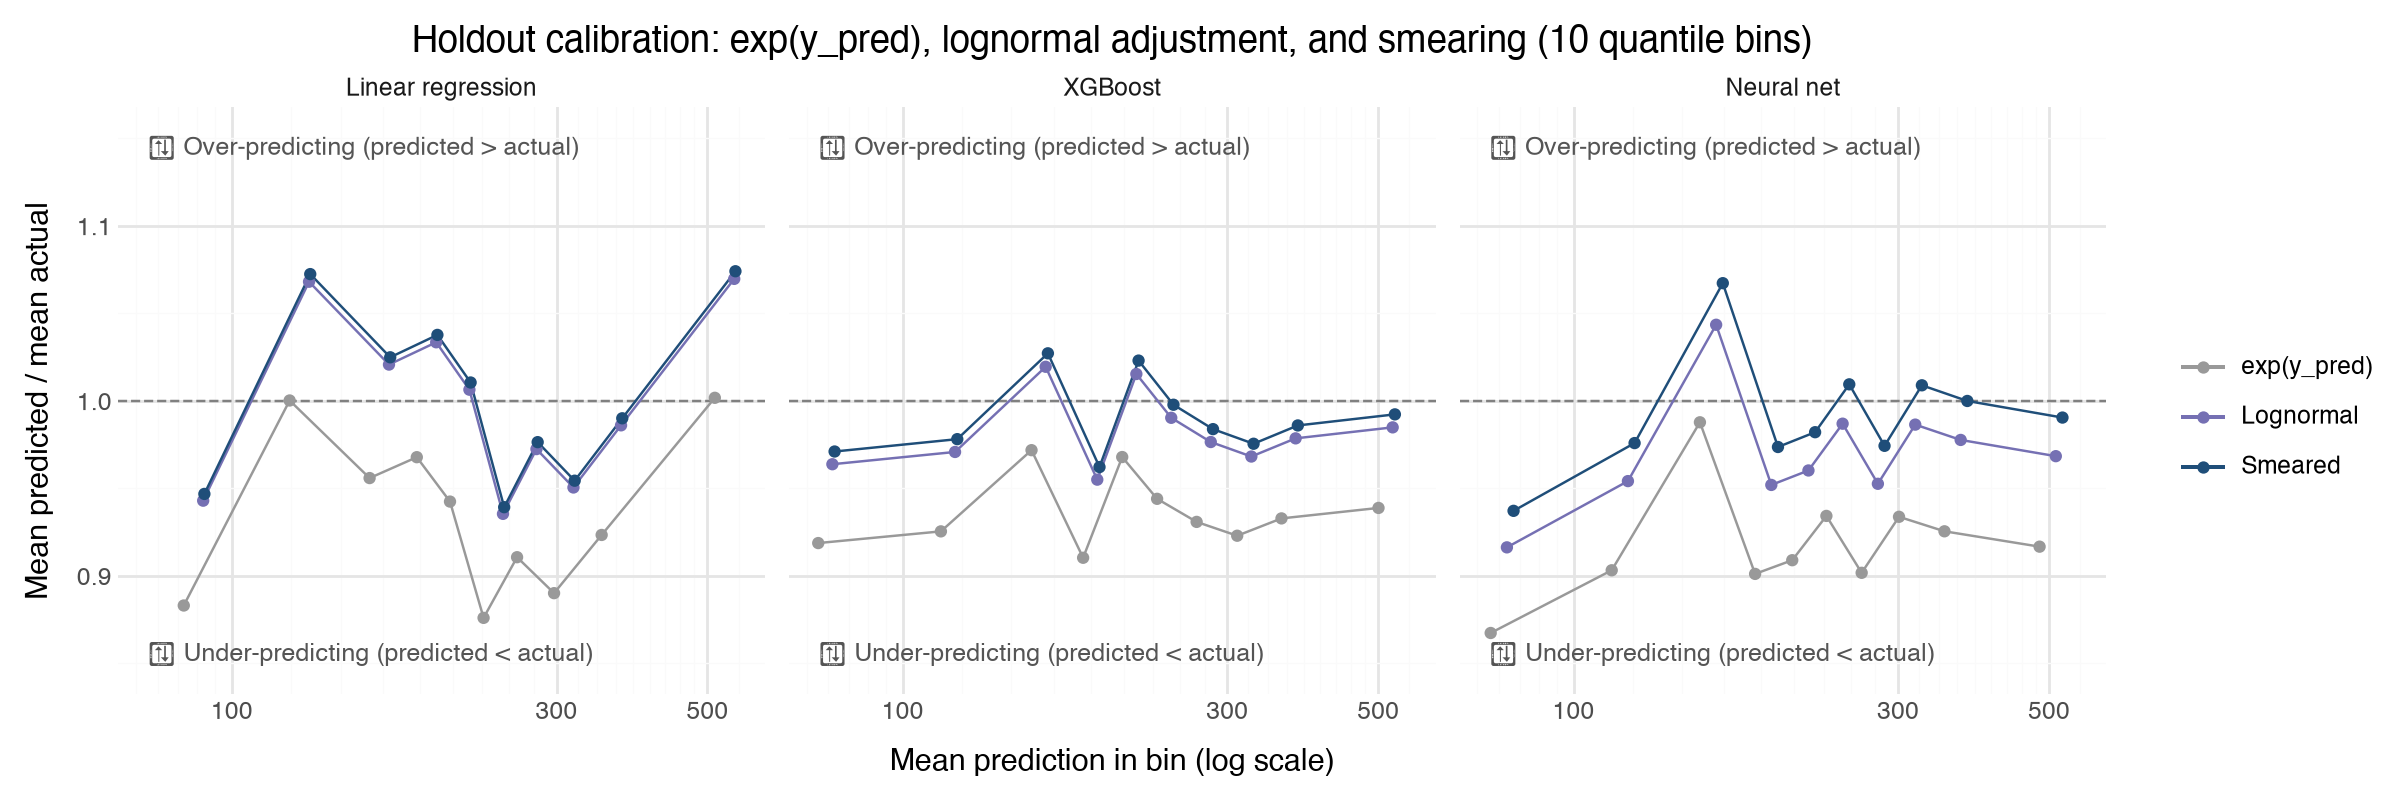

In [28]:
holdout_preds_df = preds_df[preds_df['split'] == 'holdout']

smear_long_df = pd.concat(
    [
        pd.DataFrame({'model': MODEL_LABELS[m], 'method': method, 'y': holdout_preds_df['y'], 'pred': pred})
        for m in MODEL_LABELS
        for method, pred in [
            ('exp(y_pred)', np.exp(holdout_preds_df[f'y_pred_{m}'])),
            ('Lognormal', holdout_preds_df[f'lognormal_y_pred_{m}']),
            ('Smeared', holdout_preds_df[f'smeared_y_pred_{m}']),
        ]
    ],
    ignore_index=True,
)
smear_long_df['model'] = pd.Categorical(smear_long_df['model'], categories=MODEL_ORDER)
smear_long_df['method'] = pd.Categorical(smear_long_df['method'], categories=['exp(y_pred)', 'Lognormal', 'Smeared'])

# Same binned calibration view as Step 3, since a scatter of y vs. prediction can't show a shift of a few percent
smear_calib_df = calibration_ratio(smear_long_df, 'pred', ['model', 'method'])
(
    ggplot(smear_calib_df, aes('mean_pred', 'ratio', color='method'))
    + geom_hline(yintercept=1, linetype='dashed', color='gray')
    + over_under_labels(smear_calib_df)
    + geom_line()
    + geom_point()
    + scale_color_manual(values=METHOD_COLORS)
    + facet_wrap('model', ncol=3)
    + scale_x_log10()
    + labs(
        title='Holdout calibration: exp(y_pred), lognormal adjustment, and smearing (10 quantile bins)',
        x='Mean prediction in bin (log scale)', y='Mean predicted / mean actual', color='',
    )
    + theme_minimal()
    + theme(figure_size=(12, 4))
)

In [29]:
smear_factor_by_label = {MODEL_LABELS[m]: factor for m, factor in smear_factors.items()}
lognormal_factor_by_label = {MODEL_LABELS[m]: factor for m, factor in lognormal_factors.items()}
mean_by_method = smear_long_df.groupby(['model', 'method'], observed=True)['pred'].mean().unstack('method')

bias_smeared_df = bias_df.assign(
    mean_lognormal_pred=mean_by_method['Lognormal'],
    lognormal_factor=lambda d: [lognormal_factor_by_label[label] for label in d.index],
    lognormal_bias=lambda d: d['mean_lognormal_pred'] - d['mean_y'],
    lognormal_pct_bias=lambda d: 100 * (d['mean_lognormal_pred'] / d['mean_y'] - 1),
    mean_smeared_pred=mean_by_method['Smeared'],
    smear_factor=lambda d: [smear_factor_by_label[label] for label in d.index],
    smeared_bias=lambda d: d['mean_smeared_pred'] - d['mean_y'],
    smeared_pct_bias=lambda d: 100 * (d['mean_smeared_pred'] / d['mean_y'] - 1),
)
bias_smeared_df.round(4)

,rmsle,mean_y,mean_pred,bias,pct_bias,mean_lognormal_pred,lognormal_factor,lognormal_bias,lognormal_pct_bias,mean_smeared_pred,smear_factor,smeared_bias,smeared_pct_bias
model,,,,,,,,,,,,,
Linear regression,0.3602,257.9645,241.8480,-16.1165,-6.2476,258.2600,1.0679,0.2955,0.1146,259.3134,1.0722,1.3489,0.5229
XGBoost,0.3120,257.9645,241.5684,-16.3961,-6.3560,253.4170,1.0490,-4.5475,-1.7628,255.3281,1.0570,-2.6364,-1.0220
Neural net,0.3320,257.9645,237.3637,-20.6008,-7.9859,250.7573,1.0564,-7.2072,-2.7939,256.4697,1.0805,-1.4948,-0.5795


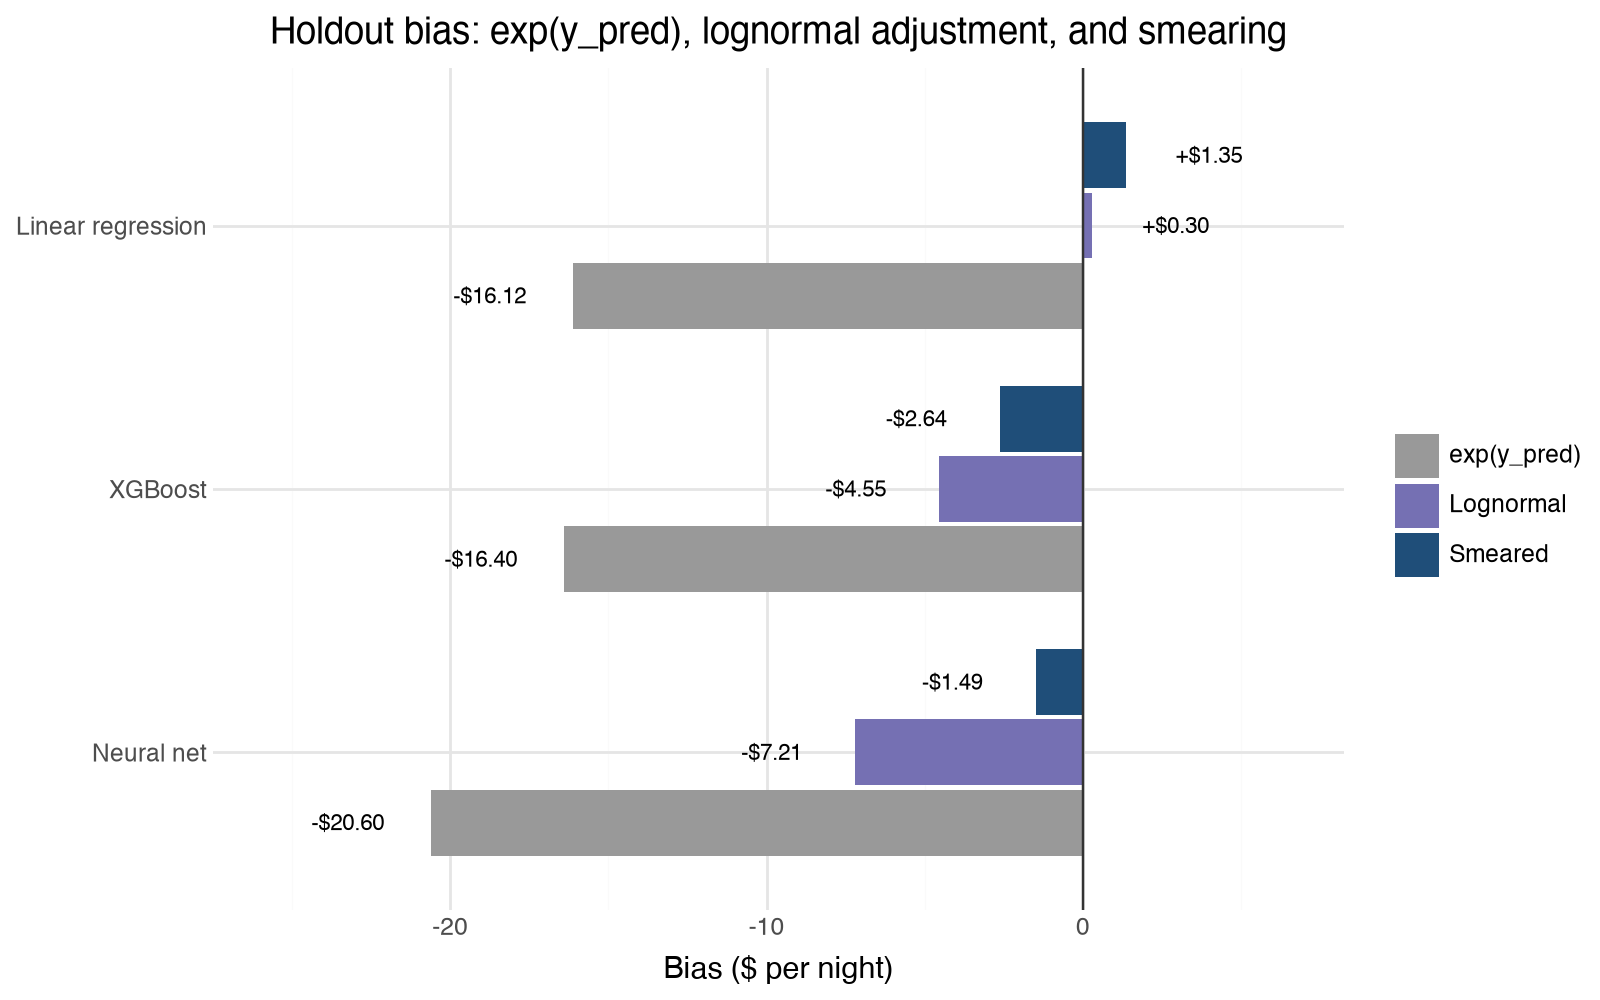

In [30]:
bias_compare_df = (
    bias_smeared_df.reset_index()
    .melt(id_vars='model', value_vars=['bias', 'lognormal_bias', 'smeared_bias'], var_name='method', value_name='bias_value')
    .assign(method=lambda d: pd.Categorical(
        d['method'].map({'bias': 'exp(y_pred)', 'lognormal_bias': 'Lognormal', 'smeared_bias': 'Smeared'}), categories=list(METHOD_COLORS)
    ))
)
bias_compare_df, pad = with_bar_labels(bias_compare_df, 'bias_value', dollars)
dodge = position_dodge(width=0.8)

(
    ggplot(bias_compare_df, aes('model', 'bias_value', fill='method'))
    + geom_col(position=dodge, width=0.75)
    + geom_hline(yintercept=0, color='#333333')
    + geom_text(aes(y='label_y', label='label', group='method'), position=dodge, size=8)
    + scale_fill_manual(values=METHOD_COLORS)
    + scale_x_discrete(limits=MODEL_ORDER[::-1])
    + expand_limits(y=[bias_compare_df['label_y'].min() - pad, bias_compare_df['label_y'].max() + pad, 0])
    + coord_flip()
    + labs(title='Holdout bias: exp(y_pred), lognormal adjustment, and smearing', x='', y='Bias ($ per night)', fill='')
    + theme_minimal()
    + theme(figure_size=(8, 5))
)

# Step 5 - Grouped smearing

Duan's estimator assumes the log-scale errors have the same distribution everywhere, so one factor fits all rows. If the spread differs between groups, a single factor over-corrects the low-variance groups and under-corrects the high-variance ones. The standard fix (Manning, 1998) is a separate smearing factor per group.

Two groupings:

* **Superhost status.** A clean two-way split with plenty of rows. Worth doing only if the residual spread actually differs between the groups; the first table below checks that.
* **Predicted-price decile.** Usable at prediction time, since it only needs the model's own prediction. Caveat: out-of-sample residuals within a bin of predicted price also pick up the model's systematic miscalibration there (e.g. cheap listings under-predicted, expensive ones over-predicted). So per-decile factors also *recalibrate* the model; they aren't purely a retransformation correction. With ~128 validation rows per decile, the factors are also noisy.

As in Step 4, factors come from each model's validation residuals. Results are on holdout.

In [31]:
def grouped_smear_preds(log_y_pred, groups, ref_residuals, ref_groups):
    """Duan smearing with a separate factor per group.

    Each group's factor is mean(exp(residual)) over the reference rows in that group. Groups with no
    reference rows fall back to the overall factor. Returns (smeared predictions, per-group factors).
    """
    ref_exp_resid = pd.Series(np.exp(np.asarray(ref_residuals)))
    factors = ref_exp_resid.groupby(np.asarray(ref_groups)).mean()
    row_factors = pd.Series(np.asarray(groups)).map(factors).fillna(ref_exp_resid.mean()).to_numpy()
    return np.exp(np.asarray(log_y_pred)) * row_factors, factors


def holdout_pct_bias_by_group(groups, method_preds):
    """Percent bias, 100 * (mean prediction / mean actual - 1), on holdout within each group, per method."""
    is_holdout_row = (preds_df['split'] == 'holdout').to_numpy()
    df = pd.DataFrame({
        'group': np.asarray(groups)[is_holdout_row],
        'y': preds_df['y'].to_numpy()[is_holdout_row],
        **{method: np.asarray(pred)[is_holdout_row] for method, pred in method_preds.items()},
    })
    grouped = df.groupby('group', observed=True)
    mean_y = grouped['y'].mean()
    out = pd.DataFrame({method: 100 * (grouped[method].mean() / mean_y - 1) for method in method_preds})
    out['n_holdout'] = grouped.size()
    return out


def plot_pct_bias_by_group(bias_long_df, title, x_label):
    return (
        ggplot(bias_long_df, aes('group', 'pct_bias', fill='method'))
        + geom_col(position=position_dodge(width=0.8), width=0.75)
        + geom_hline(yintercept=0, color='#333333')
        + facet_wrap('model', ncol=3)
        + scale_fill_manual(values=GROUPED_METHOD_COLORS)
        + labs(title=title, x=x_label, y='Holdout bias (% of mean actual)', fill='')
        + theme_minimal()
        + theme(figure_size=(13, 4.5))
    )


GROUPED_METHOD_COLORS = {'exp(y_pred)': '#999999', 'Smeared (one factor)': '#1f4e79', 'Smeared (by group)': '#d95f02'}

is_validation_row = (preds_df['split'] == 'validation').to_numpy()
validation_resid = {
    m: np.log(preds_df['y'].to_numpy()[is_validation_row]) - preds_df[f'y_pred_{m}'].to_numpy()[is_validation_row]
    for m in MODEL_LABELS
}

## Grouped by superhost status

In [32]:
# Is grouping by superhost sensible? It helps only if the residual spread (and so the smearing factor)
# differs between groups. Compare residual SD and the per-group factor on validation.
preds_df['superhost'] = listings_df['is_superhost'].map({1: 'Superhost', 0: 'Not superhost'})
validation_superhost = preds_df['superhost'].to_numpy()[is_validation_row]

pd.concat(
    {
        MODEL_LABELS[m]: (
            pd.DataFrame({'resid': resid, 'group': validation_superhost})
            .groupby('group')
            .agg(
                n_validation=('resid', 'size'),
                resid_sd=('resid', 'std'),
                smear_factor=('resid', lambda r: np.mean(np.exp(r))),
            )
        )
        for m, resid in validation_resid.items()
    },
    names=['model', 'group'],
).round(4)

n_validation  resid_sd  smear_factor
model             group                                              
Linear regression Not superhost           519    0.4548        1.1518
                  Superhost               760    0.2819        1.0179
XGBoost           Not superhost           519    0.3755        1.1175
                  Superhost               760    0.2537        1.0156
Neural net        Not superhost           519    0.4096        1.1350
                  Superhost               760    0.2650        1.0432

In [33]:
superhost_bias = {}
for m in MODEL_LABELS:
    preds_df[f'superhost_smeared_y_pred_{m}'], _ = grouped_smear_preds(
        preds_df[f'y_pred_{m}'], preds_df['superhost'], validation_resid[m], validation_superhost,
    )
    superhost_bias[MODEL_LABELS[m]] = holdout_pct_bias_by_group(preds_df['superhost'], {
        'exp(y_pred)': np.exp(preds_df[f'y_pred_{m}']),
        'Smeared (one factor)': preds_df[f'smeared_y_pred_{m}'],
        'Smeared (by group)': preds_df[f'superhost_smeared_y_pred_{m}'],
    })

superhost_bias_df = pd.concat(superhost_bias, names=['model', 'group'])
superhost_bias_df.round(2)

exp(y_pred)  Smeared (one factor)  \
model             group                                              
Linear regression Not superhost        -8.91                 -2.33   
                  Superhost            -4.53                  2.36   
XGBoost           Not superhost        -7.88                 -2.63   
                  Superhost            -5.37                  0.02   
Neural net        Not superhost        -8.18                 -0.78   
                  Superhost            -7.86                 -0.45   

                                 Smeared (by group)  n_holdout  
model             group                                         
Linear regression Not superhost                4.92        550  
                  Superhost                   -2.83        729  
XGBoost           Not superhost                2.94        550  
                  Superhost                   -3.89        729  
Neural net        Not superhost                4.22        550  
                  Superhost                   -3.88        729

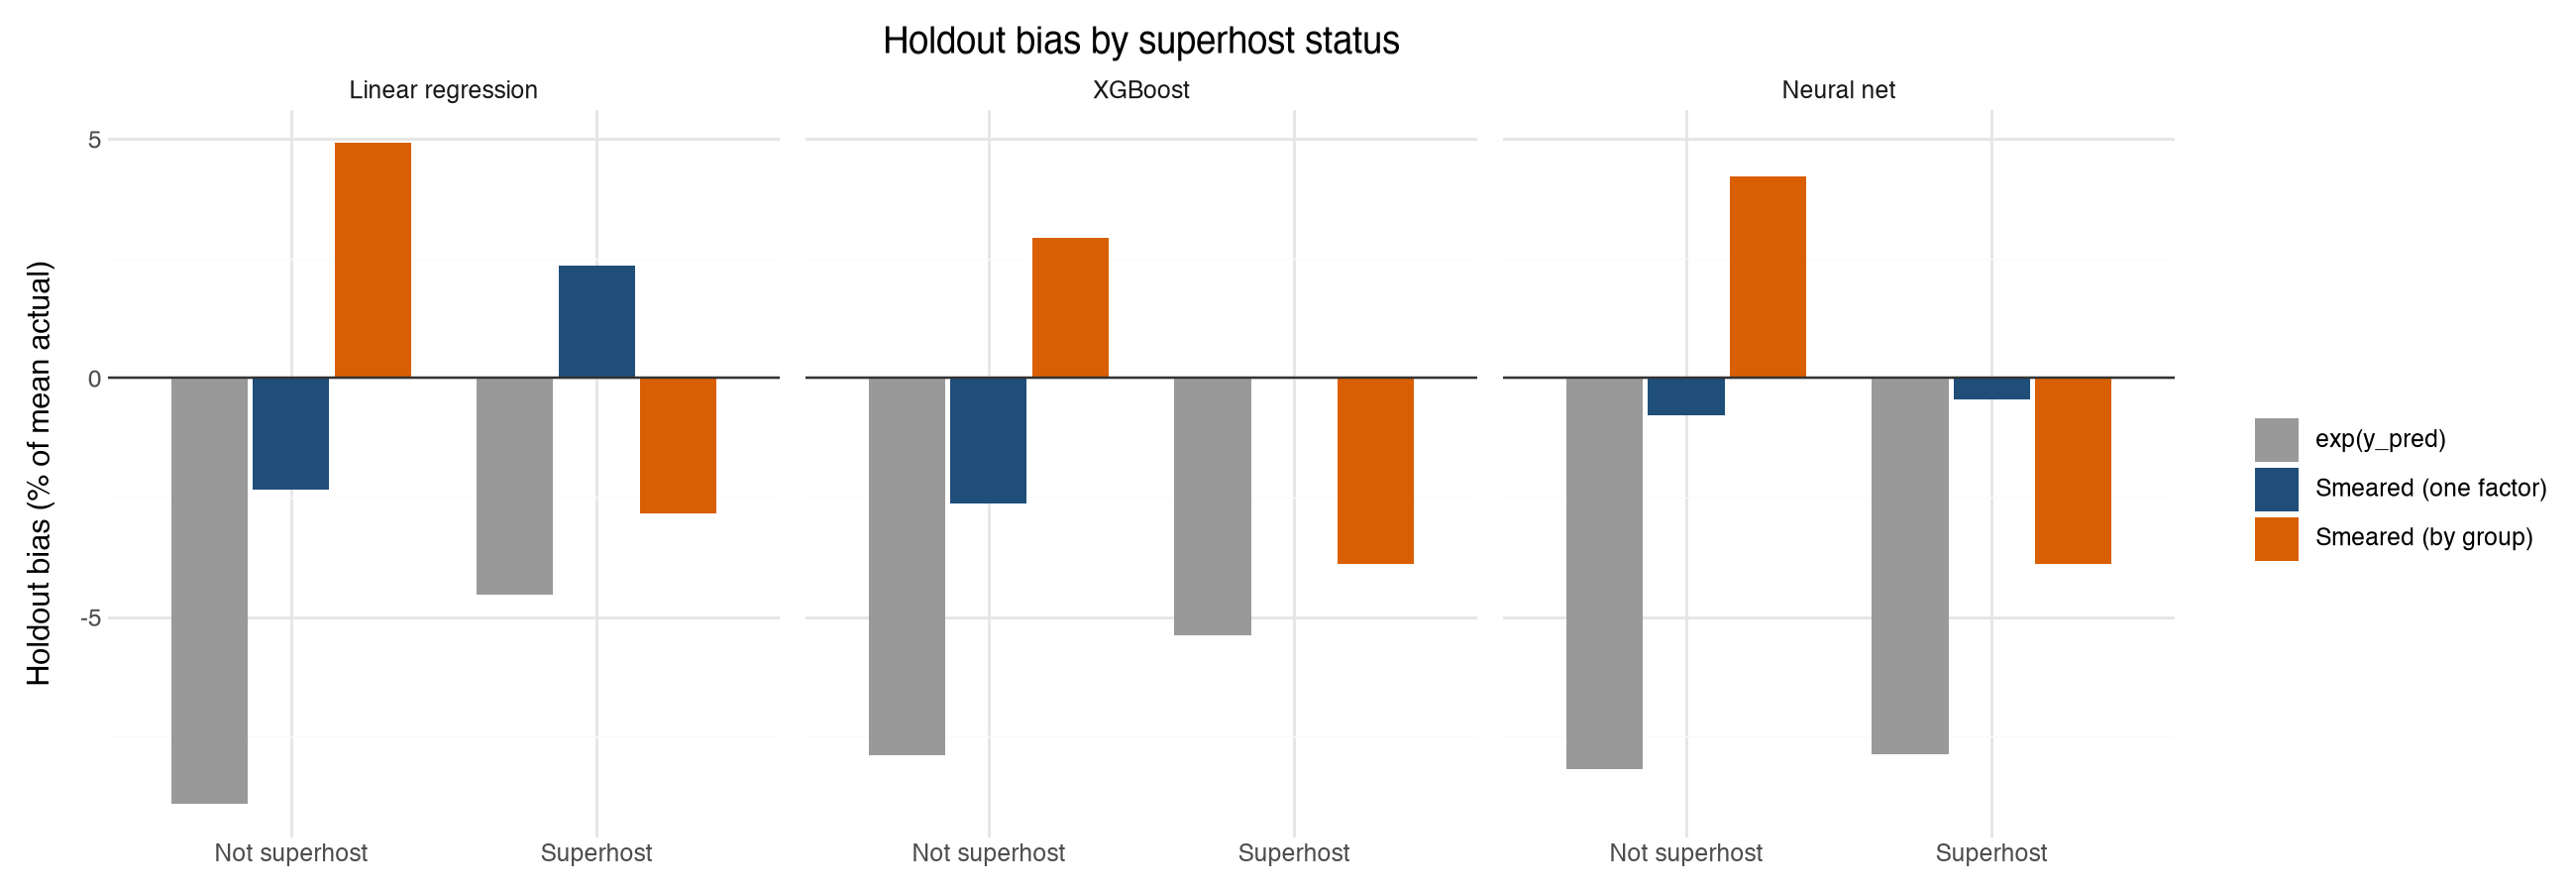

In [34]:
superhost_long_df = (
    superhost_bias_df.drop(columns='n_holdout').reset_index()
    .melt(id_vars=['model', 'group'], var_name='method', value_name='pct_bias')
    .assign(
        model=lambda d: pd.Categorical(d['model'], categories=MODEL_ORDER),
        method=lambda d: pd.Categorical(d['method'], categories=list(GROUPED_METHOD_COLORS)),
    )
)
plot_pct_bias_by_group(superhost_long_df, 'Holdout bias by superhost status', '')

## Grouped by predicted-price decile

In [35]:
# Decile edges come from each model's validation predictions, so the same
# cut points define the groups for estimating the factors and for applying them.
decile_bias, decile_factors = {}, {}
for m in MODEL_LABELS:
    validation_pred = preds_df[f'y_pred_{m}'].to_numpy()[is_validation_row]
    edges = np.quantile(validation_pred, np.linspace(0, 1, 11))
    edges[0], edges[-1] = -np.inf, np.inf  # catch final-model predictions outside the validation range
    ref_deciles = pd.cut(validation_pred, edges, labels=False) + 1
    preds_df[f'pred_decile_{m}'] = pd.cut(preds_df[f'y_pred_{m}'], edges, labels=False) + 1

    preds_df[f'decile_smeared_y_pred_{m}'], decile_factors[MODEL_LABELS[m]] = grouped_smear_preds(
        preds_df[f'y_pred_{m}'], preds_df[f'pred_decile_{m}'], validation_resid[m], ref_deciles,
    )
    decile_bias[MODEL_LABELS[m]] = holdout_pct_bias_by_group(preds_df[f'pred_decile_{m}'], {
        'exp(y_pred)': np.exp(preds_df[f'y_pred_{m}']),
        'Smeared (one factor)': preds_df[f'smeared_y_pred_{m}'],
        'Smeared (by group)': preds_df[f'decile_smeared_y_pred_{m}'],
    })

# Per-decile smearing factors. A trend across deciles (rather than noise around one value) is what
# would justify grouping; a trend also includes the model's miscalibration, as noted above.
pd.DataFrame(decile_factors).rename_axis('predicted-price decile').round(3)

,Linear regression,XGBoost,Neural net
predicted-price decile,,,
1,1.149,1.072,1.120
2,1.073,1.050,1.131
3,1.053,1.019,1.086
4,1.054,1.168,1.069
5,1.046,1.013,1.081
6,1.073,1.038,1.019
7,1.064,1.034,1.077
8,1.112,1.088,1.063
9,1.113,1.063,1.109


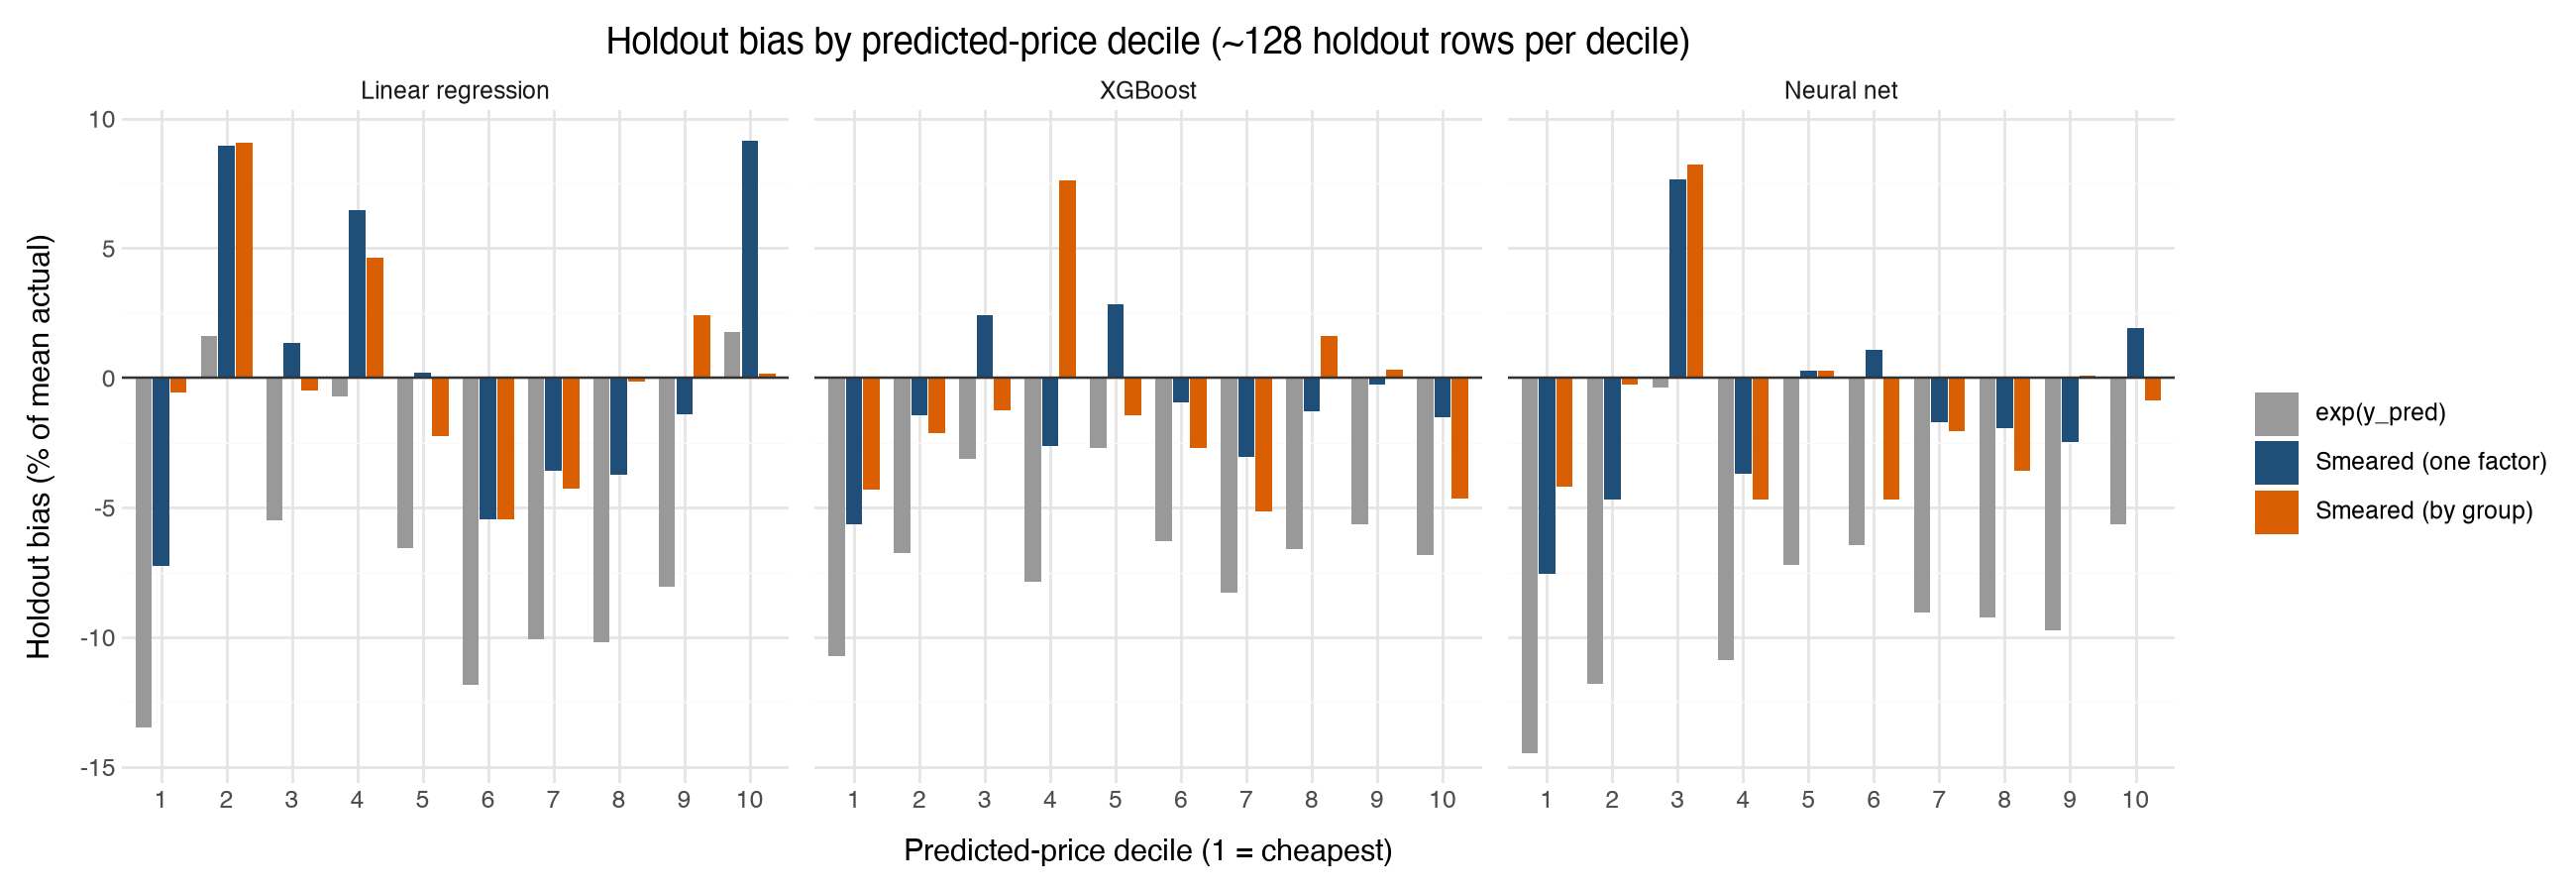

In [36]:
decile_bias_df = pd.concat(decile_bias, names=['model', 'group'])
decile_long_df = (
    decile_bias_df.drop(columns='n_holdout').reset_index()
    .melt(id_vars=['model', 'group'], var_name='method', value_name='pct_bias')
    .assign(
        model=lambda d: pd.Categorical(d['model'], categories=MODEL_ORDER),
        method=lambda d: pd.Categorical(d['method'], categories=list(GROUPED_METHOD_COLORS)),
        group=lambda d: pd.Categorical(d['group'].astype(int), categories=range(1, 11)),
    )
)
plot_pct_bias_by_group(
    decile_long_df, 'Holdout bias by predicted-price decile (~128 holdout rows per decile)',
    'Predicted-price decile (1 = cheapest)',
)

## Overall holdout bias by approach

In [37]:
# Overall holdout bias for each approach. Grouping changes the *overall* bias only a little;
# its purpose is to remove bias within groups, which the two plots above show.
is_holdout_row = (preds_df['split'] == 'holdout').to_numpy()
mean_y_holdout = preds_df.loc[is_holdout_row, 'y'].mean()
pd.DataFrame({
    MODEL_LABELS[m]: {
        'exp(y_pred)': np.exp(preds_df.loc[is_holdout_row, f'y_pred_{m}']).mean(),
        'Lognormal': preds_df.loc[is_holdout_row, f'lognormal_y_pred_{m}'].mean(),
        'Smeared (one factor)': preds_df.loc[is_holdout_row, f'smeared_y_pred_{m}'].mean(),
        'Smeared (by superhost)': preds_df.loc[is_holdout_row, f'superhost_smeared_y_pred_{m}'].mean(),
        'Smeared (by decile)': preds_df.loc[is_holdout_row, f'decile_smeared_y_pred_{m}'].mean(),
    }
    for m in MODEL_LABELS
}).T.pipe(lambda d: 100 * (d / mean_y_holdout - 1)).round(2).rename_axis('model (% bias)')

,exp(y_pred),Lognormal,Smeared (one factor),Smeared (by superhost),Smeared (by decile)
model (% bias),,,,,
Linear regression,-6.25,0.11,0.52,0.21,-0.34
XGBoost,-6.36,-1.76,-1.02,-1.22,-1.10
Neural net,-7.99,-2.79,-0.58,-0.70,-1.22
